# PROJEK JARINGAN SYARAF TIRUAN (JST)
## Prediksi Intensitas Kebakaran Hutan (Fire Radiative Power / FRP) di Kalimantan Menggunakan Data Satelit NASA FIRMS (VIIRS 375 m) 2021–2025 dan Data Cuaca NASA POWER

### Konteks & Latar Belakang Masalah
Kebakaran hutan dan lahan (karhutla) di Kalimantan menimbulkan dampak ekologis, kerugian ekonomi, gangguan kesehatan lintas wilayah, serta ancaman keselamatan bagi personel pemadaman di lapangan (seperti insiden helikopter water-bombing di Seruyan, Kalteng).

Satelit **Suomi-NPP** dengan sensor **VIIRS (Visible Infrared Imaging Radiometer Suite)** mendeteksi anomali termal aktif. Energi termal yang dilepaskan dikuantifikasi sebagai **Fire Radiative Power (FRP)** dalam MegaWatt (MW), indikator utama keganasan kobaran api.

Model yang dibangun: **Jaringan Syaraf Tiruan (JST) - Multilayer Perceptron (MLP)** berbasis **PyTorch** (CUDA bila tersedia).

**Data masukan** (dibuat oleh `fetch_hotspots.py` → `fetch_weather.py` → `build_features.py`, tersedia juga di branch `datamentah`):
- `data_karhutla_dengan_cuaca.csv` — titik api VIIRS S-NPP Kalimantan 2021–2025 + cuaca harian NASA POWER per sel 0,5° beserta fitur lag 1–30 hari.
- `nasa_viirs_kalimantan_raw.csv` — data mentah FIRMS (dipakai untuk kolom `type` jika belum ada di file cuaca).

### Ringkasan Versi Ini
Notebook ini menggabungkan **data & pipeline baru** (VIIRS S-NPP Kalimantan 2021–2025 dari arsip FIRMS + cuaca harian NASA POWER dengan lag 1–30 hari) dengan **perbaikan audit & Tahap 2**:

| # | Perubahan | Alasan / dampak |
|---|---|---|
| 1 | Hanya **kebakaran vegetasi** (`type == 0`) | 8.649 deteksi sumber panas statis/industri dan lepas pantai bukan karhutla |
| 2 | **Split berkelompok** per overpass × sel 0,5° | Split acak bocor: 16,6% titik uji punya tetangga di data latih dengan FRP **identik** (tinggal 0,4%) |
| 3 | Flag piksel I4 **terlipat (208 K)** / jenuh (367 K) + batas atas keluaran | Mencegah prediksi ekstrem yang tidak masuk akal |
| 4 | Fitur kerapatan **per overpass**, cuaca **hanya lag** (hari sebelumnya), tanpa `day_idx` | Tidak ada informasi dari masa depan |
| 5 | **11 fitur klaster api** + **30 fitur cuaca lag** | Studi ablasi: R² 0,309 → 0,349; R² skala log 0,548 → 0,624 |
| 6 | **Hyperparameter tuning** bertahap | Terpilih Tanh, 512-256-128, lr 0,002, batch 512 |
| 7 | **Ensemble 5 seed** + sebaran antar-seed | R² per seed 0,342 ± 0,010 |
| 8 | **Ambang alarm CRITICAL** dituning di validasi | Recall CRITICAL 38,5% → 67,9% |
| 9 | Pembanding baseline, XGBoost, ensemble JST+XGBoost, **uji tahun baru** (latih 2021–2023, uji 2025), **studi ablasi** | Kontribusi tiap perubahan dan kemampuan generalisasi terukur |

### Hasil (data uji berkelompok, 35.403 titik)
| Model | MSE | RMSE (MW) | MAE (MW) | R² | R² (skala log) |
|---|---|---|---|---|---|
| Baseline: rata-rata data latih | 160,23 | 12,66 | 7,16 | 0,000 | −0,241 |
| Baseline: regresi linear (log1p) + isotonic | 126,60 | 11,25 | 5,24 | 0,210 | 0,533 |
| JST ensemble 5 seed + isotonic | 104,09 | 10,20 | 4,64 | 0,350 | 0,630 |
| XGBoost (tweedie) | 100,26 | 10,01 | 4,47 | 0,374 | 0,638 |
| **Ensemble JST 0,60 + XGBoost 0,40 (model final)** | **99,14** | **9,96** | **4,50** | **0,381** | **0,642** |

Uji tahun baru (latih 2021–2023, validasi 2024, uji 2025): JST R² 0,202; XGBoost R² 0,212.

In [1]:
# 1. Import Library Utama & Konfigurasi Komputasi
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, KFold
from sklearn.neighbors import BallTree
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix

SEED = 42

# Bagian yang paling lama bisa dilewati dengan memakai hasil tersimpan (hasil_tuning_jst.csv / hasil_ablasi_jst.csv)
RUN_TUNING = True
RUN_ABLATION = True

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch Version  : {torch.__version__}')
print(f'Komputasi Device : {device.type.upper()}')
if device.type == 'cuda':
    print(f'Nama GPU         : {torch.cuda.get_device_name(0)}')
    print(f'Alokasi Memori   : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB')

PyTorch Version  : 2.15.0+cu132
Komputasi Device : CPU


### 2. Memuat Dataset NASA FIRMS 2021–2025 + Cuaca

Langkah pembersihan:
1. **Hanya kebakaran vegetasi** (`type == 0`). Arsip FIRMS juga memuat sumber panas statis/industri (`type == 2`) dan deteksi lepas pantai (`type == 3`) yang bukan karhutla.
2. **FRP < 500 MW** — dua deteksi ekstrem di atas 500 MW dibuang sebagai pencilan.
3. Setiap baris diberi ID **overpass** (tanggal UTC + siang/malam). Satu overpass = satu lintasan satelit; seluruh deteksi dalam satu overpass tersedia pada saat yang sama.

In [2]:
df = pd.read_csv('data_karhutla_dengan_cuaca.csv', low_memory=False)
if 'type' not in df.columns:
    raw_type = pd.read_csv('nasa_viirs_kalimantan_raw.csv', usecols=['latitude', 'longitude', 'frp', 'type'], low_memory=False)
    assert len(raw_type) == len(df) and np.allclose(raw_type[['latitude', 'longitude', 'frp']].values,
                                                    df[['latitude', 'longitude', 'frp']].values), 'urutan baris tidak selaras'
    df['type'] = raw_type['type'].values

n_awal = len(df)
print('Jumlah deteksi per type (0=vegetasi, 2=sumber statis, 3=lepas pantai):', df['type'].value_counts().sort_index().to_dict())
df = df[(df['type'] == 0) & (df['frp'] < 500)].reset_index(drop=True)

df['is_day'] = (df['daynight'] == 'D').astype(int)
df['confidence_score'] = df['confidence'].map({'l': 1, 'n': 2, 'h': 3}).astype(int)
df['acq_date'] = pd.to_datetime(df['acq_date'])
df['year'] = df['acq_date'].dt.year
df['day_idx'] = (df['acq_date'] - df['acq_date'].min()).dt.days
df['overpass'] = df['acq_date'].dt.strftime('%Y-%m-%d') + '_' + df['daynight']

print(f'Data setelah pembersihan: {len(df):,} dari {n_awal:,} deteksi.')
print(f'Periode data : {df["acq_date"].min().date()} s/d {df["acq_date"].max().date()} '
      f'({df["acq_date"].dt.date.nunique():,} hari, {df["overpass"].nunique():,} overpass)')
display(df.groupby('year').agg(titik_api=('frp', 'size'), median_FRP=('frp', 'median'),
                               mean_FRP=('frp', 'mean'), porsi_CRITICAL=('frp', lambda s: (s >= 20).mean())).round(3))

Jumlah deteksi per type (0=vegetasi, 2=sumber statis, 3=lepas pantai): {0: 184457, 2: 8130, 3: 519}
Data setelah pembersihan: 184,455 dari 193,106 deteksi.
Periode data : 2021-01-03 s/d 2025-12-31 (1,671 hari, 2,918 overpass)


,titik_api,median_FRP,mean_FRP,porsi_CRITICAL
year,,,,
2021,16966,5.50,8.848,0.083
2022,14090,5.52,8.765,0.087
2023,89215,5.47,8.937,0.088
2024,31514,6.10,10.542,0.116
2025,32670,6.40,10.857,0.130


### 3. Eksplorasi Data, Korelasi Fitur, & Distribusi Target

,count,mean,std,min,25%,50%,75%,max
latitude,184455.0,-0.834270,1.695247,-4.17890,-2.479555,-0.57246,0.467340,4.35303
longitude,184455.0,112.995595,2.658234,108.82637,110.614190,112.58028,115.101515,119.49996
bright_ti4,184455.0,334.875331,14.390916,208.00000,330.610000,335.73000,342.580000,367.00000
scan,184455.0,0.456311,0.082544,0.32000,0.390000,0.43000,0.510000,0.80000
track,184455.0,0.473612,0.108129,0.36000,0.380000,0.44000,0.550000,0.78000
bright_ti5,184455.0,293.114105,6.852864,150.00000,289.820000,293.33000,297.160000,374.57000
is_day,184455.0,0.827064,0.378193,0.00000,1.000000,1.00000,1.000000,1.00000
confidence_score,184455.0,1.989813,0.278628,1.00000,2.000000,2.00000,2.000000,3.00000
frp,184455.0,9.529781,13.912437,0.00000,3.290000,5.73000,10.360000,408.38000


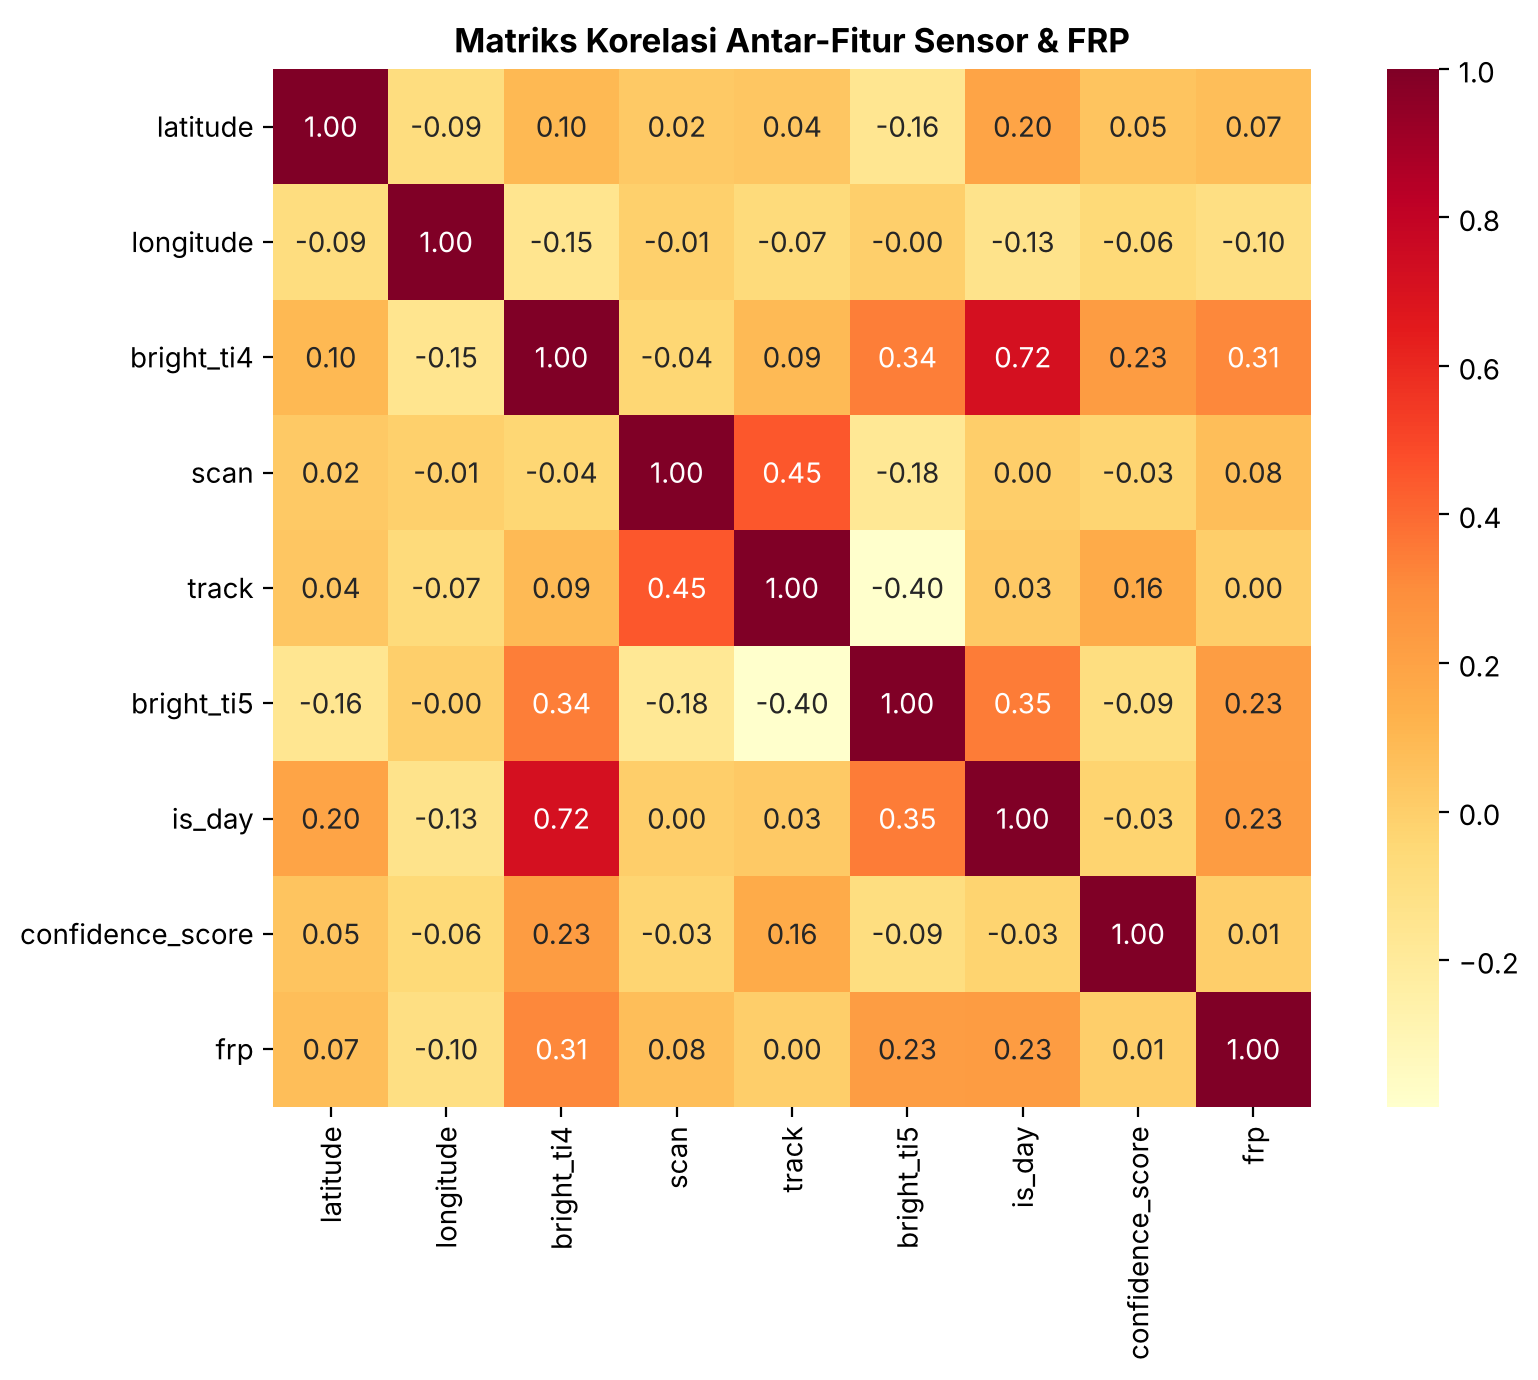

In [3]:
SENSOR_COLS = ['latitude', 'longitude', 'bright_ti4', 'scan', 'track',
               'bright_ti5', 'is_day', 'confidence_score', 'frp']

display(df[SENSOR_COLS].describe().T)

plt.figure(figsize=(9, 7))
sns.heatmap(df[SENSOR_COLS].corr(), annot=True, fmt='.2f', cmap='YlOrRd',
            cbar=True, square=True)
plt.title('Matriks Korelasi Antar-Fitur Sensor & FRP', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('matriks_korelasi_fitur.png', dpi=300, bbox_inches='tight')
plt.show()

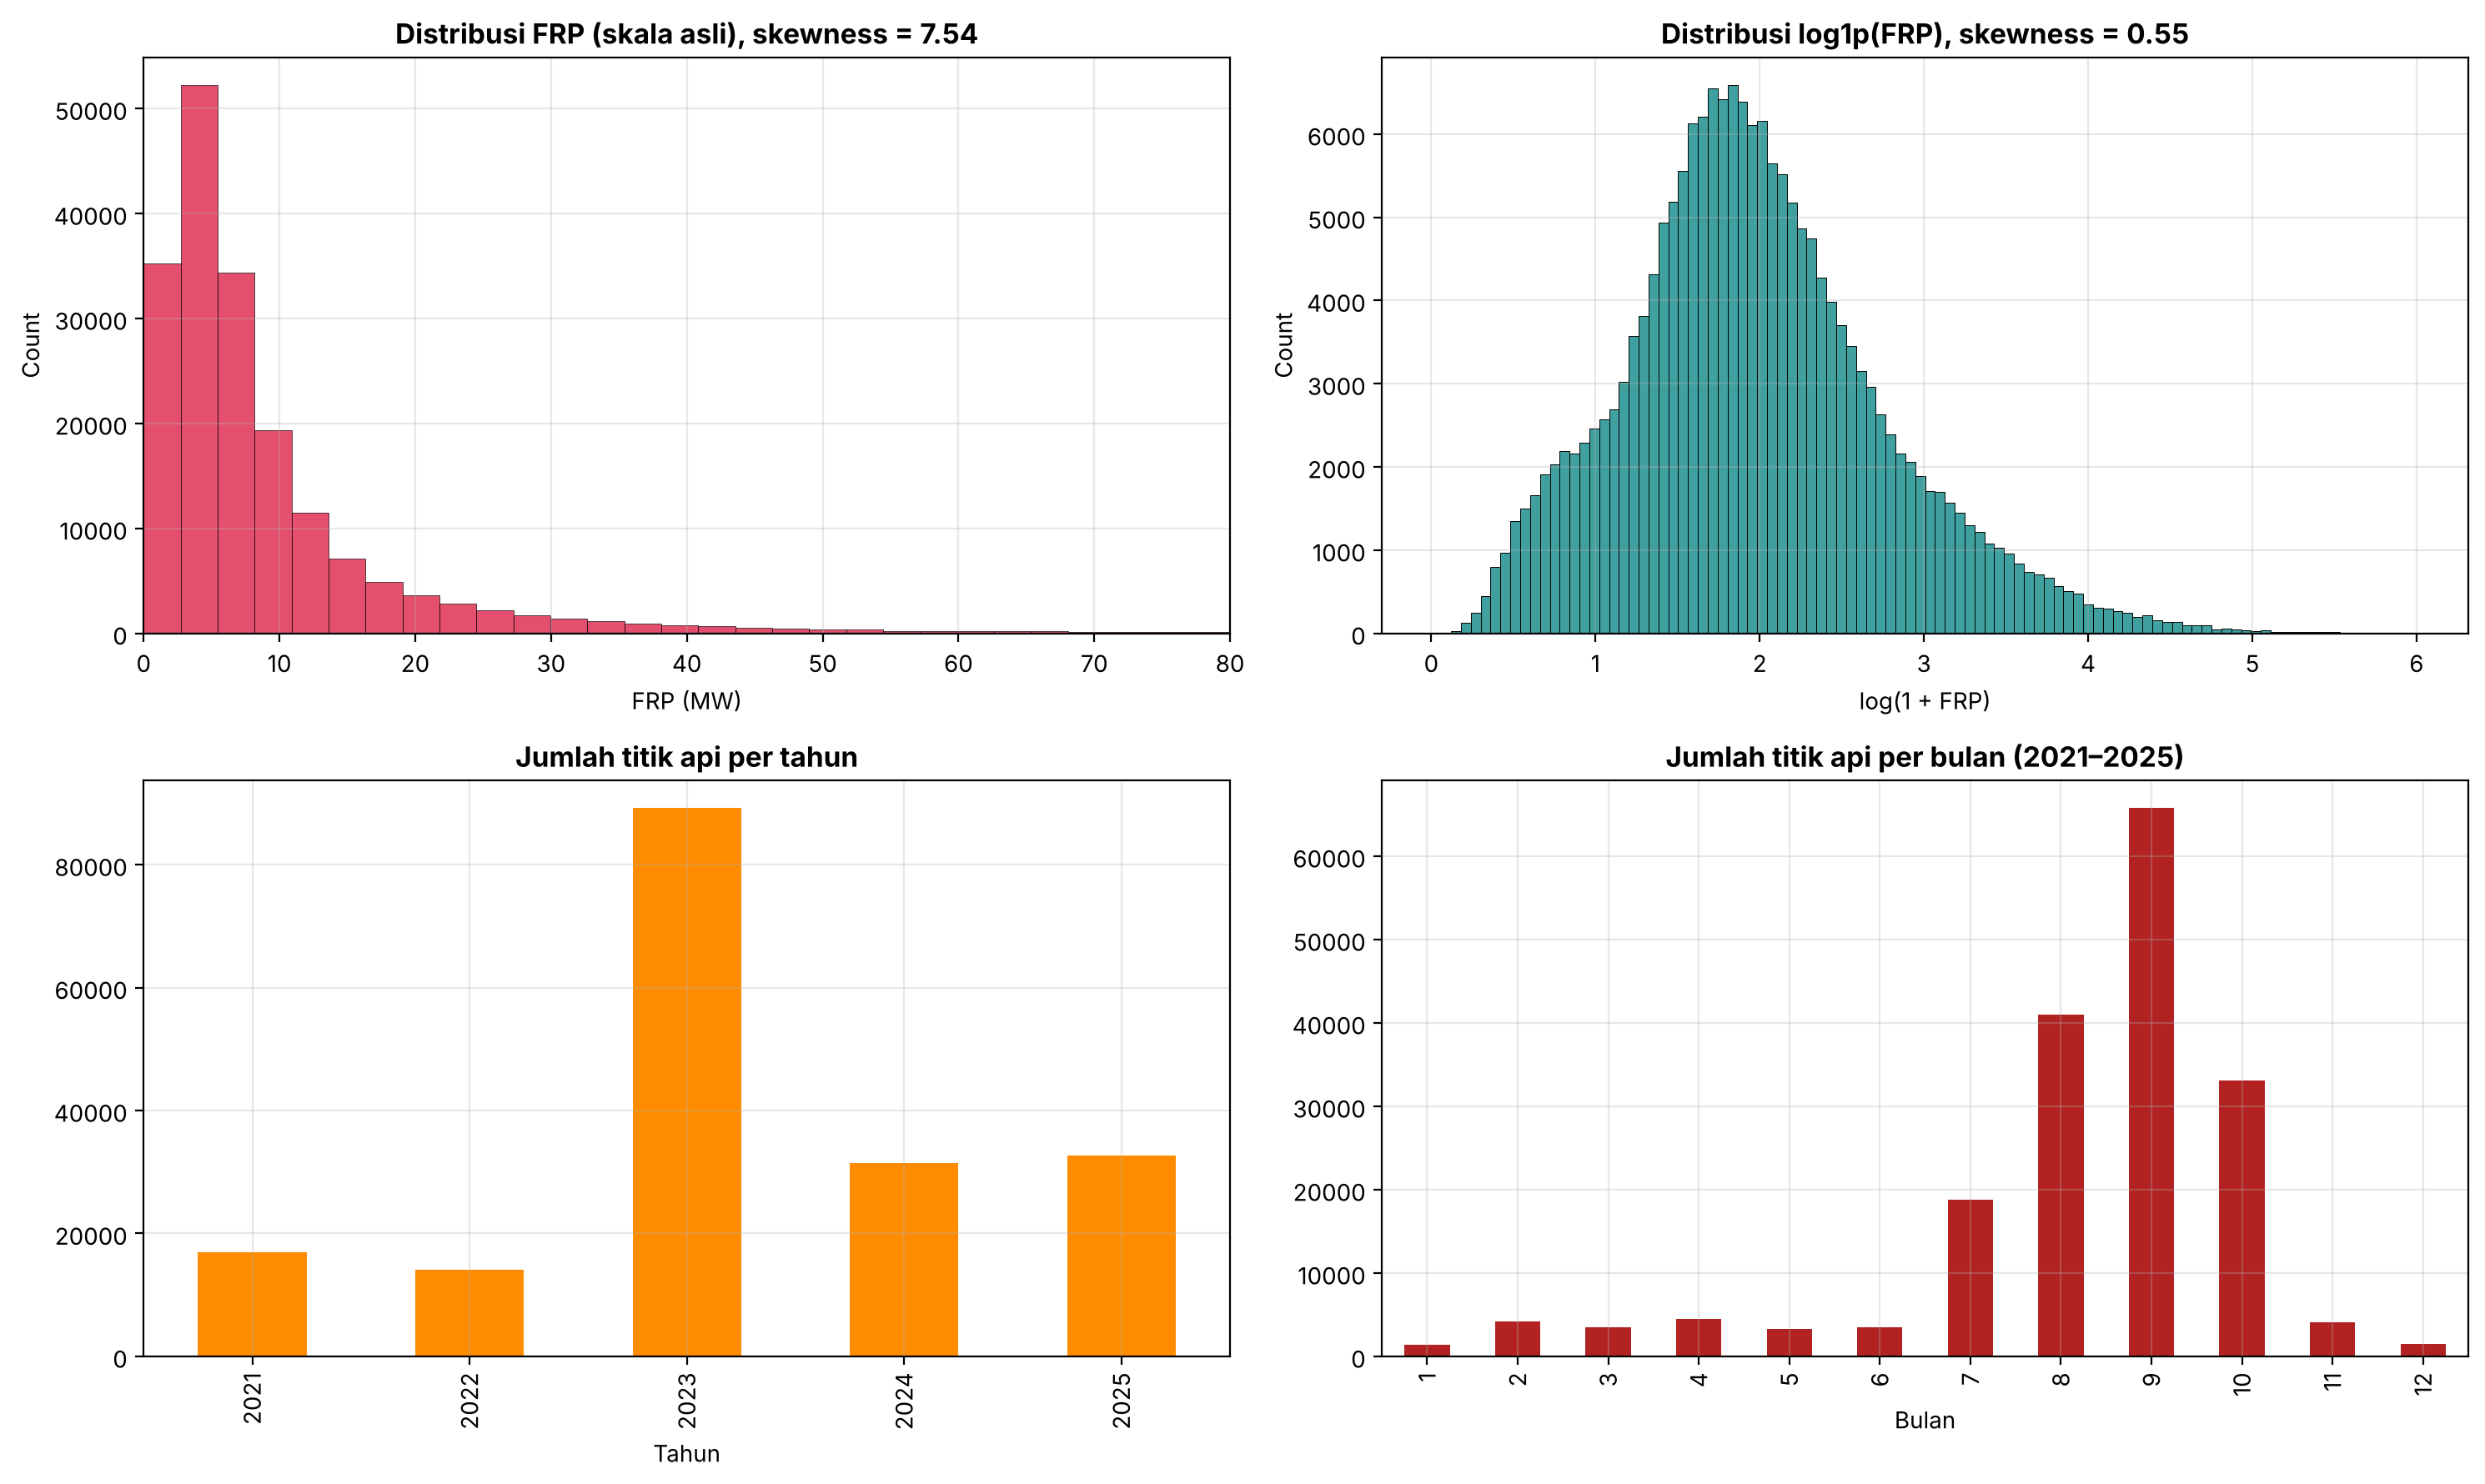

Median FRP : 5.73 MW
Mean FRP   : 9.53 MW
Maks FRP   : 408.38 MW
Sampel FRP >= 20 MW (CRITICAL): 18,399 (9.97%)


In [4]:
# Distribusi target & pola waktu kebakaran
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
sns.histplot(df['frp'], bins=150, ax=axes[0, 0], color='crimson')
axes[0, 0].set_xlim(0, 80)
axes[0, 0].set_title(f'Distribusi FRP (skala asli), skewness = {df["frp"].skew():.2f}', fontweight='bold')
axes[0, 0].set_xlabel('FRP (MW)')
sns.histplot(np.log1p(df['frp']), bins=100, ax=axes[0, 1], color='teal')
axes[0, 1].set_title(f'Distribusi log1p(FRP), skewness = {np.log1p(df["frp"]).skew():.2f}', fontweight='bold')
axes[0, 1].set_xlabel('log(1 + FRP)')
df.groupby('year').size().plot.bar(ax=axes[1, 0], color='darkorange')
axes[1, 0].set_title('Jumlah titik api per tahun', fontweight='bold'); axes[1, 0].set_xlabel('Tahun')
df.groupby(df['acq_date'].dt.month).size().plot.bar(ax=axes[1, 1], color='firebrick')
axes[1, 1].set_title('Jumlah titik api per bulan (2021–2025)', fontweight='bold'); axes[1, 1].set_xlabel('Bulan')
for ax in axes.ravel():
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('distribusi_frp_dan_waktu.png', dpi=200, bbox_inches='tight')
plt.show()

print(f'Median FRP : {df["frp"].median():.2f} MW')
print(f'Mean FRP   : {df["frp"].mean():.2f} MW')
print(f'Maks FRP   : {df["frp"].max():.2f} MW')
print(f'Sampel FRP >= 20 MW (CRITICAL): {(df["frp"] >= 20).sum():,} ({(df["frp"] >= 20).mean() * 100:.2f}%)')

### 3b. Kualitas Data Sensor: Saturasi & *Fold-over* Kanal I4

Menurut dokumentasi produk VIIRS 375 m, nilai `bright_ti4` berada pada rentang **208–367 K**. Piksel api yang terlalu panas diberi nilai saturasi **367 K**, dan pada api yang sangat ekstrem nilai digitalnya **terlipat (*fold-over*)** sehingga tampak bersuhu sangat rendah (208 K). Piksel 208 K karenanya **bukan api dingin**, melainkan api yang melampaui batas ukur sensor.

Selain itu, FRP produk 375 m dihitung dari kanal M13 (750 m) yang tidak tersedia di CSV FIRMS, sehingga pada piksel jenuh fitur suhu I4 tidak lagi membawa informasi intensitas.

In [5]:
folded = df['bright_ti4'] <= 208.0
saturated = df['bright_ti4'] >= 367.0
print(f'Piksel I4 jenuh (367 K)   : {saturated.sum():,} ({saturated.mean() * 100:.2f}%) | '
      f'median FRP {df.loc[saturated, "frp"].median():.2f} MW')
print(f'Piksel I4 normal          : {(~saturated & ~folded).sum():,} | '
      f'median FRP {df.loc[~saturated & ~folded, "frp"].median():.2f} MW')
print(f'Piksel I4 terlipat (208 K): {folded.sum()} | median FRP {df.loc[folded, "frp"].median():.2f} MW')

# Korelasi Pearson meremehkan hubungan monotonik pada target yang sangat menceng
display(pd.DataFrame({'Pearson': df[SENSOR_COLS].corr()['frp'],
                      'Spearman': df[SENSOR_COLS].corr(method='spearman')['frp']})
        .drop('frp').round(3))

Piksel I4 jenuh (367 K)   : 6,275 (3.40%) | median FRP 13.85 MW
Piksel I4 normal          : 178,123 | median FRP 5.55 MW
Piksel I4 terlipat (208 K): 57 | median FRP 95.21 MW


,Pearson,Spearman
latitude,0.072,0.101
longitude,-0.099,-0.152
bright_ti4,0.314,0.701
scan,0.076,0.175
track,0.002,0.085
bright_ti5,0.226,0.291
is_day,0.234,0.549
confidence_score,0.006,0.045


### 4. Preprocessing: Feature Engineering, Splitting, & Normalisasi

**Fitur sensor dasar (8)**: `latitude`, `longitude`, `bright_ti4`, `scan`, `track`, `bright_ti5`, `is_day`, `confidence_score`. Untuk piksel terlipat, `bright_ti4` diset ke 367 K sebelum fitur turunan dihitung.

**Flag kualitas I4 (2)**: `ti4_folded` (`bright_ti4 == 208 K`) dan `ti4_saturated` (`bright_ti4 >= 367 K` atau terlipat).

**Fitur turunan termal & geometris (7)**

| Fitur | Rumus | Alasan |
|---|---|---|
| `delta_t` | `bright_ti4 - bright_ti5` | Kontras suhu api terhadap latar |
| `pixel_area` | `scan * track` | FRP adalah daya total per piksel, jadi piksel lebih luas → FRP lebih besar |
| `ti4_day` | `bright_ti4 * is_day` | Interaksi suhu–waktu |
| `ti4_ti5_ratio` | `bright_ti4 / bright_ti5` | Kontras relatif terhadap kondisi latar |
| `delta_t_day` | `delta_t * is_day` | Kontras termal terkoreksi siang/malam |
| `conf_high`, `conf_nominal` | one-hot `confidence_score` | Keyakinan deteksi |

**Fitur waktu (5)**: `hour_frac`, `hour_sin`, `hour_cos` (jam akuisisi UTC, siklik) serta `doy_sin`, `doy_cos` (hari dalam tahun, menangkap musim kemarau/hujan). `day_idx` tidak dipakai karena untuk tanggal baru nilainya selalu di luar rentang data latih.

**Fitur kerapatan hotspot (4)** — per **overpass**: `cell_density`, `neigh_density` (blok 3×3 sel 0,5°), `overpass_total`, `neigh_density_norm`.

**Fitur klaster api (11)** — piksel api tetangga dalam radius 0,5 km dan 1 km pada overpass yang sama. FRP produk 375 m dihitung dari piksel M13 750 m yang mencakup beberapa piksel 375 m, sehingga piksel tetangga membawa informasi energi total api.

| Fitur | Definisi |
|---|---|
| `mir_excess_area` | Kelebihan radiansi MIR 3,74 µm (hukum Planck: `L(T_I4) − L(T_I5)`) × luas piksel |
| `nb_count_{r}km` | Jumlah piksel api lain dalam radius *r* |
| `nb_max_ti4_{r}km`, `nb_mean_ti4_{r}km` | Suhu I4 maksimum dan rata-rata di sekitar piksel |
| `nb_sat_{r}km` | Jumlah piksel jenuh/terlipat dalam radius *r* |
| `nb_sum_excess_{r}km` | `log(1 + Σ mir_excess_area)` dalam radius *r* |

**Fitur cuaca lag (30)** — dari NASA POWER per sel 0,5°, dihitung `build_features.py` dari hari-hari **sebelum** deteksi (`shift(1)`) untuk jendela 1, 3, 7, 14, 30 hari: akumulasi hujan (`precip_acc`), rata-rata kelembapan (`rh_mean`), suhu (`temp_mean`), angin (`wind_mean`), kelembapan tanah minimum (`soil_min`), dan VPD maksimum (`vpd_max`).

Cuaca **hari yang sama** (rata-rata harian) tidak dipakai karena mencakup jam setelah satelit lewat (informasi masa depan); kolom `month` juga tidak dipakai karena sudah terwakili `doy_sin`/`doy_cos`.

**Total 67 fitur masukan.** Target dilatih sebagai `log1p(FRP)`; `StandardScaler` hanya di-*fit* pada data latih.

In [6]:
BASE_FEATURES = ['latitude', 'longitude', 'bright_ti4', 'scan', 'track',
                 'bright_ti5', 'is_day', 'confidence_score']
TARGET = 'frp'
I4_FOLD_K, I4_SAT_K = 208.0, 367.0
GRID_DEG = 0.5
CLUSTER_RADII_KM = (0.5, 1.0)
EARTH_RADIUS_KM = 6371.0

def fix_i4(frame):
    # Piksel terlipat (208 K) = api di atas batas ukur: tandai lalu set ke nilai saturasi.
    out = frame.copy()
    is_folded = frame['bright_ti4'] <= I4_FOLD_K
    out['ti4_folded'] = is_folded.astype(np.float32)
    out['ti4_saturated'] = (is_folded | (frame['bright_ti4'] >= I4_SAT_K)).astype(np.float32)
    out.loc[is_folded, 'bright_ti4'] = I4_SAT_K
    return out

def add_thermal_features(frame):
    out = frame.copy()
    out['delta_t'] = frame['bright_ti4'] - frame['bright_ti5']
    out['pixel_area'] = frame['scan'] * frame['track']
    out['ti4_day'] = frame['bright_ti4'] * frame['is_day']
    out['ti4_ti5_ratio'] = frame['bright_ti4'] / frame['bright_ti5']
    out['delta_t_day'] = out['delta_t'] * frame['is_day']
    out['conf_high'] = (frame['confidence_score'] == 3).astype(np.float32)
    out['conf_nominal'] = (frame['confidence_score'] == 2).astype(np.float32)
    return out

def add_temporal_features(frame):
    out = frame.copy()
    minutes = (frame['acq_time'] // 100) * 60 + (frame['acq_time'] % 100)
    out['hour_frac'] = minutes / 1440.0
    out['hour_sin'] = np.sin(2 * np.pi * out['hour_frac'])
    out['hour_cos'] = np.cos(2 * np.pi * out['hour_frac'])
    doy = pd.to_datetime(frame['acq_date']).dt.dayofyear
    out['doy_sin'] = np.sin(2 * np.pi * doy / 365.25)
    out['doy_cos'] = np.cos(2 * np.pi * doy / 365.25)
    return out

def grid_cell(frame):
    return (np.floor(frame['latitude'] / GRID_DEG).astype(int).values,
            np.floor(frame['longitude'] / GRID_DEG).astype(int).values)

def build_density_tables(frame):
    # Kerapatan hotspot per (overpass, sel grid 0,5 derajat); hanya memakai koordinat & overpass.
    g = frame[['overpass', 'latitude', 'longitude']].copy()
    g['glat'], g['glon'] = grid_cell(g)
    keys = ['overpass', 'glat', 'glon']
    cell = g.groupby(keys).size().rename('cell_density').reset_index()
    frames = []
    for d_lat in (-1, 0, 1):
        for d_lon in (-1, 0, 1):
            tmp = cell.copy()
            tmp['glat'] = tmp['glat'] + d_lat
            tmp['glon'] = tmp['glon'] + d_lon
            frames.append(tmp)
    neigh = (pd.concat(frames).groupby(keys)['cell_density']
             .sum().rename('neigh_density').reset_index())
    total = g.groupby('overpass').size().rename('overpass_total').reset_index()
    return cell, neigh, total

def add_density_features(frame, tables):
    cell, neigh, total = tables
    keys = ['overpass', 'glat', 'glon']
    g = frame[['overpass', 'latitude', 'longitude']].copy()
    g['glat'], g['glon'] = grid_cell(g)
    g = (g.merge(cell, on=keys, how='left')
          .merge(neigh, on=keys, how='left')
          .merge(total, on='overpass', how='left'))
    cols = ['cell_density', 'neigh_density', 'overpass_total']
    g[cols] = g[cols].fillna(0)
    g['neigh_density_norm'] = (g['neigh_density'] / g['overpass_total'].replace(0, np.nan)).fillna(0)
    return g[DENSITY].reset_index(drop=True)

def planck_radiance(T, wavelength_um=3.74):
    # Radiansi benda hitam (W m^-2 sr^-1 um^-1) pada panjang gelombang kanal I4
    c1, c2 = 1.191042e8, 1.4387752e4
    return c1 / (wavelength_um ** 5 * (np.exp(c2 / (wavelength_um * T)) - 1.0))

NB_STATS = ['nb_count', 'nb_max_ti4', 'nb_mean_ti4', 'nb_sat', 'nb_sum_excess']

def add_cluster_features(frame):
    # Statistik piksel api tetangga dalam radius r pada overpass yang sama (hanya fitur masukan, tanpa target).
    f = frame.reset_index(drop=True)
    excess = ((planck_radiance(f['bright_ti4'].values) - planck_radiance(f['bright_ti5'].values))
              .clip(min=0) * f['pixel_area'].values)
    ti4, sat = f['bright_ti4'].values, f['ti4_saturated'].values
    out = {'mir_excess_area': excess}
    for r in CLUSTER_RADII_KM:
        for s in NB_STATS:
            out[f'{s}_{r}km'] = np.zeros(len(f))
    for _, idx in f.groupby('overpass').indices.items():
        coords = np.radians(f.loc[idx, ['latitude', 'longitude']].values)
        tree = BallTree(coords, metric='haversine')
        for r in CLUSTER_RADII_KM:
            for row, nb in zip(idx, tree.query_radius(coords, r=r / EARTH_RADIUS_KM)):
                nb = idx[nb]
                out[f'nb_count_{r}km'][row] = len(nb) - 1
                out[f'nb_max_ti4_{r}km'][row] = ti4[nb].max()
                out[f'nb_mean_ti4_{r}km'][row] = ti4[nb].mean()
                out[f'nb_sat_{r}km'][row] = sat[nb].sum()
                out[f'nb_sum_excess_{r}km'][row] = np.log1p(excess[nb].sum())
    return pd.DataFrame(out)[CLUSTER]

I4_FLAGS = ['ti4_folded', 'ti4_saturated']
THERMAL = ['delta_t', 'pixel_area', 'ti4_day', 'ti4_ti5_ratio',
           'delta_t_day', 'conf_high', 'conf_nominal']
TEMPORAL = ['hour_frac', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos']
DENSITY = ['cell_density', 'neigh_density', 'overpass_total', 'neigh_density_norm']
CLUSTER = ['mir_excess_area'] + [f'{s}_{r}km' for r in CLUSTER_RADII_KM for s in NB_STATS]
WEATHER_LAG = [f'{v}_{lag}d' for lag in (1, 3, 7, 14, 30)
               for v in ['precip_acc', 'rh_mean', 'temp_mean', 'wind_mean', 'soil_min', 'vpd_max']]
FEATURES = BASE_FEATURES + I4_FLAGS + THERMAL + TEMPORAL + DENSITY + CLUSTER + WEATHER_LAG

t0 = time.time()
df_fe = add_temporal_features(add_thermal_features(fix_i4(df))).reset_index(drop=True)
density_tables = build_density_tables(df_fe)
df_fe = pd.concat([df_fe, add_density_features(df_fe, density_tables), add_cluster_features(df_fe)], axis=1)
assert df_fe[FEATURES].notna().all().all(), 'ada nilai kosong pada fitur'

print(f'Jumlah fitur total: {len(FEATURES)} (dibuat dalam {time.time() - t0:.0f} detik)')
spearman = df_fe[CLUSTER + WEATHER_LAG + ['frp']].corr(method='spearman')['frp'].drop('frp')
display(spearman.reindex(spearman.abs().sort_values(ascending=False).index).head(15).round(3).to_frame('Spearman vs FRP'))

Jumlah fitur total: 67 (dibuat dalam 6 detik)


,Spearman vs FRP
nb_mean_ti4_0.5km,0.720
nb_mean_ti4_1.0km,0.718
nb_max_ti4_0.5km,0.700
nb_max_ti4_1.0km,0.681
mir_excess_area,0.640
nb_sum_excess_0.5km,0.590
nb_sum_excess_1.0km,0.531
nb_sat_1.0km,0.262
nb_sat_0.5km,0.247
nb_count_1.0km,0.181


#### Splitting berkelompok (tanpa kebocoran)

Satu kebakaran terdeteksi sebagai banyak piksel 375 m yang bersebelahan dalam satu overpass, dan karena FRP dihitung dari piksel M13 750 m, piksel tetangga sering memiliki **FRP yang persis sama**. Split acak menaruh piksel-piksel kembar ini di data latih dan data uji sekaligus, sehingga skor uji terlalu optimistis (dibuktikan di bagian 8c).

Karena itu data dibagi per **kelompok = overpass × sel grid 0,5°**: seluruh piksel dalam satu kelompok selalu berada di sisi yang sama (latih, validasi, atau uji). Proporsi ±64% latih, 16% validasi, 20% uji. Generalisasi ke **tahun yang belum pernah dilihat** diuji terpisah di bagian 8c (latih 2021–2023, validasi 2024, uji 2025).

In [7]:
X = df_fe[FEATURES].values.astype(np.float32)
y = df_fe[TARGET].values.astype(np.float64)

glat, glon = grid_cell(df_fe)
groups = (df_fe['overpass'] + '_' + pd.Series(glat).astype(str) + '_' + pd.Series(glon).astype(str)).values

def grouped_split(idx, test_size, seed=SEED):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(gss.split(idx, groups=groups[idx]))
    return idx[a], idx[b]

idx_all = np.arange(len(df_fe))
idx_train_full, idx_test = grouped_split(idx_all, test_size=0.2)
idx_train, idx_val = grouped_split(idx_train_full, test_size=0.2)
assert not (set(groups[idx_train]) & set(groups[idx_test])), 'kelompok bocor ke data uji'
assert not (set(groups[idx_train]) & set(groups[idx_val])), 'kelompok bocor ke data validasi'

X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f'Jumlah kelompok (overpass x sel 0,5°): {len(np.unique(groups)):,}')
print(f'Jumlah Data Latih (Train) : {len(X_train):,} sampel')
print(f'Jumlah Data Validasi (Val): {len(X_val):,} sampel')
print(f'Jumlah Data Uji (Test)    : {len(X_test):,} sampel')
print(f'Bentuk X_train            : {X_train_scaled.shape}')

Jumlah kelompok (overpass x sel 0,5°): 35,360
Jumlah Data Latih (Train) : 118,625 sampel
Jumlah Data Validasi (Val): 30,427 sampel
Jumlah Data Uji (Test)    : 35,403 sampel
Bentuk X_train            : (118625, 67)


### 5. Arsitektur Jaringan Syaraf Tiruan (Deep Multilayer Perceptron)

Arsitektur dibuat fleksibel (jumlah & lebar hidden layer, fungsi aktivasi, BatchNorm, dropout) agar bisa dibandingkan pada tahap *hyperparameter tuning* (bagian 6b). Konfigurasi awal:

1. **Input Layer**: 67 neuron.
2. **Hidden Layer 1**: 256 neuron → `BatchNorm1d` → aktivasi → Dropout `0.2`.
3. **Hidden Layer 2**: 128 neuron → `BatchNorm1d` → aktivasi → Dropout `0.1`.
4. **Hidden Layer 3**: 64 neuron → `BatchNorm1d` → aktivasi → Dropout `0.05`.
5. **Output Layer**: 1 neuron `Linear` → memprediksi `log1p(FRP)`.

In [8]:
ACTIVATIONS = {'relu': nn.ReLU, 'gelu': nn.GELU, 'silu': nn.SiLU, 'tanh': nn.Tanh}

class KarhutlaJST(nn.Module):
    def __init__(self, input_dim, hidden=(256, 128, 64), drop=(0.2, 0.1, 0.05), act='gelu', batchnorm=True):
        super(KarhutlaJST, self).__init__()
        layers, prev = [], input_dim
        for i, h in enumerate(hidden):
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(ACTIVATIONS[act]())
            if i < len(drop) and drop[i] > 0:
                layers.append(nn.Dropout(drop[i]))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

model = KarhutlaJST(input_dim=X_train_scaled.shape[1]).to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal Parameter JST (konfigurasi awal): {total_params:,} bobot & bias.')

KarhutlaJST(
  (network): Sequential(
    (0): Linear(in_features=67, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): GELU(approximate='none')
    (11): Dropout(p=0.05, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

Total Parameter JST (konfigurasi awal): 59,521 bobot & bias.


### 6. Pelatihan Model: Backpropagation, LR Scheduler, & Early Stopping

- **Loss**: MSE pada ruang `log1p(FRP)`.
- **Optimizer**: AdamW (`weight_decay = 1e-4`); learning rate & batch size ditentukan lewat tuning.
- **Scheduler**: `ReduceLROnPlateau` (faktor 0.5, patience 10).
- **Early stopping**: berhenti bila val loss tidak membaik 30 epoch; bobot terbaik dipulihkan.
- **Epoch maksimum**: 300.

Fungsi `train_jst` juga mendukung konfigurasi desain Tahap 1 (Adam, tanpa scheduler/early stopping, MSE pada FRP mentah) untuk studi ablasi di bagian 8d.

In [9]:
def train_jst(X_tr_scaled, y_tr, X_va_scaled, y_va, hidden=(256, 128, 64), drop=(0.2, 0.1, 0.05),
              act='gelu', batchnorm=True, lr=1e-3, weight_decay=1e-4, batch_size=512, log_target=True,
              optimizer_name='adamw', use_scheduler=True, epochs_max=300, patience=30, seed=SEED, verbose=True):
    set_seed(seed)
    net = KarhutlaJST(X_tr_scaled.shape[1], hidden, drop, act, batchnorm).to(device)
    to_target = np.log1p if log_target else (lambda v: v)
    train_ds = TensorDataset(torch.tensor(X_tr_scaled, dtype=torch.float32),
                             torch.tensor(to_target(y_tr), dtype=torch.float32).unsqueeze(1))
    val_ds = TensorDataset(torch.tensor(X_va_scaled, dtype=torch.float32),
                           torch.tensor(to_target(y_va), dtype=torch.float32).unsqueeze(1))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=2048, shuffle=False)

    criterion = nn.MSELoss()
    if optimizer_name == 'adamw':
        optimizer = optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        optimizer = optim.Adam(net.parameters(), lr=lr)
    scheduler = (optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)
                 if use_scheduler else None)
    hist = {'train_loss': [], 'val_loss': []}
    best_val, best_state, bad_epochs = float('inf'), None, 0

    for epoch in range(1, epochs_max + 1):
        net.train()
        running = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = criterion(net(batch_x), batch_y)
            loss.backward()
            optimizer.step()
            running += loss.item() * batch_x.size(0)
        epoch_train_loss = running / len(train_ds)

        net.eval()
        running = 0.0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                running += criterion(net(batch_x), batch_y).item() * batch_x.size(0)
        epoch_val_loss = running / len(val_ds)

        current_lr = optimizer.param_groups[0]['lr']
        if scheduler is not None:
            scheduler.step(epoch_val_loss)
        hist['train_loss'].append(epoch_train_loss)
        hist['val_loss'].append(epoch_val_loss)

        if epoch_val_loss < best_val - 1e-6:
            best_val, bad_epochs = epoch_val_loss, 0
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        else:
            bad_epochs += 1

        if verbose and (epoch % 10 == 0 or epoch == 1):
            print(f'Epoch [{epoch:03d}/{epochs_max}] | Train MSE: {epoch_train_loss:.5f} | '
                  f'Val MSE: {epoch_val_loss:.5f} | LR: {current_lr:.2e} | no-improve: {bad_epochs}/{patience}')
        if patience and bad_epochs >= patience:
            if verbose:
                print(f'Early stopping pada epoch {epoch} (val loss terbaik {best_val:.5f}).')
            break

    if patience:                      # tanpa early stopping: pakai bobot epoch terakhir
        net.load_state_dict(best_state)
    net.log_target = log_target
    return net, hist

def jst_predict(net, Z_scaled, log_cap):
    net.eval()
    with torch.no_grad():
        out = net(torch.tensor(np.asarray(Z_scaled), dtype=torch.float32).to(device)).cpu().numpy().ravel()
    if getattr(net, 'log_target', True):
        return np.clip(np.expm1(np.minimum(out, log_cap)), 0, None)
    return np.clip(out, 0, None)

LOG_CAP = np.log1p(y_train.max())   # batas atas keluaran: FRP maksimum data latih

### 6b. Hyperparameter Tuning Bertahap

Pencarian dilakukan bertahap pada **data validasi** (kriteria: MSE validasi terbaik di ruang `log1p`, yaitu loss yang dioptimasi). Data uji tidak disentuh. Agar efisien pada ±118 ribu data latih, setiap percobaan tuning memakai anggaran sama: maksimum 80 epoch dengan early stopping patience 15.

| Tahap | Yang dibandingkan |
|---|---|
| A | Fungsi aktivasi: ReLU, GELU, SiLU, Tanh |
| B | Arsitektur: 128-64-32, 256-128-64, 512-256-128 |
| C | Learning rate (3e-4, 1e-3, 2e-3) dan batch size (512, 1024) |

Setiap tahap memakai pemenang tahap sebelumnya. Hasil disimpan ke `hasil_tuning_jst.csv`; set `RUN_TUNING = False` (sel pertama) untuk memakai hasil tersimpan tanpa melatih ulang.

In [10]:
ARCHS = {'128-64-32': ((128, 64, 32), (0.2, 0.1, 0.05)),
         '256-128-64': ((256, 128, 64), (0.2, 0.1, 0.05)),
         '512-256-128': ((512, 256, 128), (0.2, 0.1, 0.05))}
cfg = dict(hidden=(256, 128, 64), drop=(0.2, 0.1, 0.05), act='gelu', lr=1e-3, batch_size=512)
TUNE_BUDGET = dict(epochs_max=80, patience=15)

if RUN_TUNING:
    tuning_rows, cache = [], {}

    def trial(stage, c):
        key = (c['act'], tuple(c['hidden']), c['lr'], c['batch_size'])
        if key not in cache:
            t0 = time.time()
            _, hist = train_jst(X_train_scaled, y_train, X_val_scaled, y_val, verbose=False, **TUNE_BUDGET, **c)
            cache[key] = min(hist['val_loss'])
            tuning_rows.append({'Tahap': stage, 'Aktivasi': c['act'], 'Arsitektur': '-'.join(map(str, c['hidden'])),
                                'Learning rate': c['lr'], 'Batch size': c['batch_size'],
                                'Val MSE (log)': cache[key], 'Epoch': len(hist['val_loss']),
                                'Detik': round(time.time() - t0)})
            print(f'{stage:24s} | {c["act"]:5s} | {"-".join(map(str, c["hidden"])):12s} | lr {c["lr"]:.0e} | '
                  f'batch {c["batch_size"]:4d} | val MSE (log) {cache[key]:.5f}')
        return cache[key]

    scores = {a: trial('A. Fungsi aktivasi', {**cfg, 'act': a}) for a in ['relu', 'gelu', 'silu', 'tanh']}
    cfg['act'] = min(scores, key=scores.get)

    scores = {n: trial('B. Arsitektur', {**cfg, 'hidden': h, 'drop': d}) for n, (h, d) in ARCHS.items()}
    cfg['hidden'], cfg['drop'] = ARCHS[min(scores, key=scores.get)]

    scores = {(lr, bs): trial('C. Learning rate & batch', {**cfg, 'lr': lr, 'batch_size': bs})
              for lr, bs in [(3e-4, 512), (1e-3, 512), (2e-3, 512), (1e-3, 1024)]}
    cfg['lr'], cfg['batch_size'] = min(scores, key=scores.get)

    tuning_df = pd.DataFrame(tuning_rows)
    tuning_df.to_csv('hasil_tuning_jst.csv', index=False)
else:
    tuning_df = pd.read_csv('hasil_tuning_jst.csv')
    best = tuning_df.loc[tuning_df['Val MSE (log)'].idxmin()]
    cfg['act'] = best['Aktivasi']
    cfg['hidden'], cfg['drop'] = ARCHS[best['Arsitektur']]
    cfg['lr'], cfg['batch_size'] = float(best['Learning rate']), int(best['Batch size'])

BEST_CFG = dict(cfg)
display(tuning_df.round(5))
print('Konfigurasi terbaik:', BEST_CFG)

A. Fungsi aktivasi       | relu  | 256-128-64   | lr 1e-03 | batch  512 | val MSE (log) 0.22503


A. Fungsi aktivasi       | gelu  | 256-128-64   | lr 1e-03 | batch  512 | val MSE (log) 0.22721


A. Fungsi aktivasi       | silu  | 256-128-64   | lr 1e-03 | batch  512 | val MSE (log) 0.22661


A. Fungsi aktivasi       | tanh  | 256-128-64   | lr 1e-03 | batch  512 | val MSE (log) 0.22441


B. Arsitektur            | tanh  | 128-64-32    | lr 1e-03 | batch  512 | val MSE (log) 0.22455


B. Arsitektur            | tanh  | 512-256-128  | lr 1e-03 | batch  512 | val MSE (log) 0.22380


C. Learning rate & batch | tanh  | 512-256-128  | lr 3e-04 | batch  512 | val MSE (log) 0.22469


C. Learning rate & batch | tanh  | 512-256-128  | lr 2e-03 | batch  512 | val MSE (log) 0.22243


C. Learning rate & batch | tanh  | 512-256-128  | lr 1e-03 | batch 1024 | val MSE (log) 0.22388


,Tahap,Aktivasi,Arsitektur,Learning rate,Batch size,Val MSE (log),Epoch,Detik
0,A. Fungsi aktivasi,relu,256-128-64,0.0010,512,0.22503,48,76
1,A. Fungsi aktivasi,gelu,256-128-64,0.0010,512,0.22721,48,84
2,A. Fungsi aktivasi,silu,256-128-64,0.0010,512,0.22661,50,82
3,A. Fungsi aktivasi,tanh,256-128-64,0.0010,512,0.22441,80,130
4,B. Arsitektur,tanh,128-64-32,0.0010,512,0.22455,80,97
5,B. Arsitektur,tanh,512-256-128,0.0010,512,0.22380,60,156
6,C. Learning rate & batch,tanh,512-256-128,0.0003,512,0.22469,80,205
7,C. Learning rate & batch,tanh,512-256-128,0.0020,512,0.22243,57,150
8,C. Learning rate & batch,tanh,512-256-128,0.0010,1024,0.22388,80,201


Konfigurasi terbaik: {'hidden': (512, 256, 128), 'drop': (0.2, 0.1, 0.05), 'act': 'tanh', 'lr': 0.002, 'batch_size': 512}


### 6c. Pelatihan Model Final: Ensemble 5 Seed

Hasil satu kali pelatihan JST bergantung pada inisialisasi bobot acak (*seed*). Model final dilatih **5 kali dengan seed berbeda** memakai konfigurasi terbaik (anggaran penuh: 300 epoch, patience 30); prediksinya dirata-rata (ensemble) sehingga lebih stabil, dan sebaran skor antar-seed dilaporkan.

In [11]:
N_SEEDS = 5
models, histories = [], []
print('Memulai proses pelatihan model JST final...')
for s in range(N_SEEDS):
    t0 = time.time()
    net, hist = train_jst(X_train_scaled, y_train, X_val_scaled, y_val, seed=SEED + s, verbose=(s == 0), **BEST_CFG)
    models.append(net)
    histories.append(hist)
    print(f'Seed {SEED + s}: {len(hist["val_loss"])} epoch | val MSE (log) terbaik {min(hist["val_loss"]):.5f} | '
          f'{time.time() - t0:.0f} detik\n')

model, history = models[0], histories[0]
epochs_run = len(history['train_loss'])
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Parameter per model: {total_params:,} bobot & bias | arsitektur {BEST_CFG["hidden"]} | aktivasi {BEST_CFG["act"]}')

Memulai proses pelatihan model JST final...


Epoch [001/300] | Train MSE: 0.61460 | Val MSE: 0.28257 | LR: 2.00e-03 | no-improve: 0/30


Epoch [010/300] | Train MSE: 0.23363 | Val MSE: 0.23772 | LR: 2.00e-03 | no-improve: 0/30


Epoch [020/300] | Train MSE: 0.22214 | Val MSE: 0.22797 | LR: 2.00e-03 | no-improve: 5/30


Epoch [030/300] | Train MSE: 0.20906 | Val MSE: 0.22631 | LR: 1.00e-03 | no-improve: 3/30


Epoch [040/300] | Train MSE: 0.19865 | Val MSE: 0.22375 | LR: 5.00e-04 | no-improve: 13/30


... (4 outputs left out)

Seed 43: 79 epoch | val MSE (log) terbaik 0.22495 | 205 detik



Seed 44: 83 epoch | val MSE (log) terbaik 0.22454 | 217 detik



Seed 45: 67 epoch | val MSE (log) terbaik 0.22433 | 175 detik



Seed 46: 62 epoch | val MSE (log) terbaik 0.22394 | 162 detik

Parameter per model: 200,961 bobot & bias | arsitektur (512, 256, 128) | aktivasi tanh


### 7. Evaluasi JST & Kalibrasi Isotonic

Model memprediksi `log1p(FRP)`; `expm1` mengembalikan ke MW. Dua pengaman dipakai:

1. **Batas atas keluaran**: keluaran log dibatasi pada `log1p(FRP maksimum data latih)`.
2. **Kalibrasi isotonic** di-*fit* pada data **validasi** (bukan test). Karena `expm1(E[log y]) ≤ E[y]` pada distribusi menceng, prediksi mentah cenderung *underestimate* **mean**; fungsi monotonik ini mengoreksi bias tersebut tanpa mengubah urutan prediksi.

In [12]:
def mse_of(a, b):
    return mean_squared_error(a, b)

def regression_metrics(y_true, p):
    m = mse_of(y_true, p)
    return {'MSE': m, 'RMSE': np.sqrt(m), 'MAE': mean_absolute_error(y_true, p), 'R2': r2_score(y_true, p),
            'R2 (log)': r2_score(np.log1p(y_true), np.log1p(np.clip(p, 0, None)))}

def predict_jst(frame_or_scaled, is_scaled=False):
    Z = frame_or_scaled if is_scaled else scaler.transform(frame_or_scaled)
    return np.mean([jst_predict(m, Z, LOG_CAP) for m in models], axis=0)

# Sebaran skor antar-seed (masing-masing dikalibrasi pada validasi)
seed_rows = []
for s, m in enumerate(models):
    pv, pt = jst_predict(m, X_val_scaled, LOG_CAP), jst_predict(m, X_test_scaled, LOG_CAP)
    iso_s = IsotonicRegression(out_of_bounds='clip').fit(pv, y_val)
    seed_rows.append({'Seed': SEED + s, **regression_metrics(y_test, iso_s.predict(pt))})
seed_df = pd.DataFrame(seed_rows)
print('SEBARAN SKOR JST PER SEED (data uji):')
display(seed_df.round(4))
display(seed_df.drop(columns='Seed').agg(['mean', 'std']).round(4))

# Ensemble 5 seed + kalibrasi isotonic
y_pred = predict_jst(X_test_scaled, is_scaled=True)
y_pred_val = predict_jst(X_val_scaled, is_scaled=True)
iso = IsotonicRegression(out_of_bounds='clip').fit(y_pred_val, y_val)
y_pred_cal = np.clip(iso.predict(y_pred), 0, None)
y_pred_val_cal = np.clip(iso.predict(y_pred_val), 0, None)

print(f'Prediksi mentah maksimum: val {y_pred_val.max():.1f} MW | test {y_pred.max():.1f} MW '
      f'(FRP aktual maksimum data latih {y_train.max():.1f} MW)')
print('\nPENGARUH KALIBRASI (data validasi):')
display(pd.DataFrame({
    'Tahap': ['JST ensemble (expm1 mentah)', 'JST ensemble + kalibrasi isotonic'],
    'MSE (val)': [f'{mse_of(y_val, y_pred_val):.4f}', f'{mse_of(y_val, y_pred_val_cal):.4f}'],
    'MAE (val)': [f'{mean_absolute_error(y_val, y_pred_val):.4f}',
                  f'{mean_absolute_error(y_val, y_pred_val_cal):.4f}'],
}))

jst_metrics = regression_metrics(y_test, y_pred_cal)
mse, rmse, mae, r2 = (jst_metrics[k] for k in ['MSE', 'RMSE', 'MAE', 'R2'])
print(f'\nHASIL EVALUASI JST (ENSEMBLE {N_SEEDS} SEED) PADA DATA UJI BERKELOMPOK (setelah kalibrasi):')
display(pd.DataFrame({
    'Metrik': ['Mean Squared Error (MSE)', 'Root Mean Squared Error (RMSE)',
               'Mean Absolute Error (MAE)', 'R-squared (R2 Score)', 'R-squared skala log1p'],
    'Nilai': [f'{mse:.4f}', f'{rmse:.4f} MW', f'{mae:.4f} MW', f'{r2:.4f}', f'{jst_metrics["R2 (log)"]:.4f}']
}))

SEBARAN SKOR JST PER SEED (data uji):


,Seed,MSE,RMSE,MAE,R2,R2 (log)
0,42,104.3264,10.2140,4.6615,0.3486,0.6243
1,43,104.3101,10.2132,4.6562,0.3487,0.6243
2,44,107.9302,10.3889,4.7197,0.3261,0.6186
3,45,105.8635,10.2890,4.6870,0.3390,0.6232
4,46,104.2364,10.2096,4.6731,0.3492,0.6237


,MSE,RMSE,MAE,R2,R2 (log)
mean,105.3333,10.2630,4.6795,0.3423,0.6228
std,1.6038,0.0779,0.0254,0.0100,0.0024


Prediksi mentah maksimum: val 91.7 MW | test 87.6 MW (FRP aktual maksimum data latih 391.1 MW)

PENGARUH KALIBRASI (data validasi):


,Tahap,MSE (val),MAE (val)
0,JST ensemble (expm1 mentah),165.0083,4.4724
1,JST ensemble + kalibrasi isotonic,148.1975,4.8612



HASIL EVALUASI JST (ENSEMBLE 5 SEED) PADA DATA UJI BERKELOMPOK (setelah kalibrasi):


,Metrik,Nilai
0,Mean Squared Error (MSE),104.0917
1,Root Mean Squared Error (RMSE),10.2025 MW
2,Mean Absolute Error (MAE),4.6380 MW
3,R-squared (R2 Score),0.3501
4,R-squared skala log1p,0.6298


In [13]:
# Analisis konsentrasi error: berapa persen sampel menyumbang mayoritas MSE?
sq_err = (y_test - y_pred_cal) ** 2
order = np.argsort(sq_err)[::-1]
share = np.cumsum(sq_err[order]) / sq_err.sum()
rows = []
for p in [0.005, 0.01, 0.014, 0.02, 0.05, 0.10]:
    k = max(int(len(y_test) * p), 1)
    rows.append({'Persentil sampel terburuk': f'{p * 100:.1f}%',
                 'Kontribusi terhadap MSE': f'{share[k - 1] * 100:.1f}%',
                 'Ambang error (MW)': f'{np.sqrt(sq_err[order][k - 1]):.2f}'})
display(pd.DataFrame(rows))
print(f'Median error absolut: {np.median(np.abs(y_test - y_pred_cal)):.3f} MW')
print(f'Rata-rata prediksi  : {y_pred_cal.mean():.3f} MW | rata-rata aktual: {y_test.mean():.3f} MW')

,Persentil sampel terburuk,Kontribusi terhadap MSE,Ambang error (MW)
0,0.5%,43.5%,60.19
1,1.0%,55.6%,42.49
2,1.4%,61.5%,36.24
3,2.0%,67.6%,29.50
4,5.0%,81.2%,16.49
5,10.0%,89.1%,10.13


Median error absolut: 2.102 MW
Rata-rata prediksi  : 9.469 MW | rata-rata aktual: 9.307 MW


### 8. Visualisasi Hasil Pembelajaran & Prediksi vs Aktual

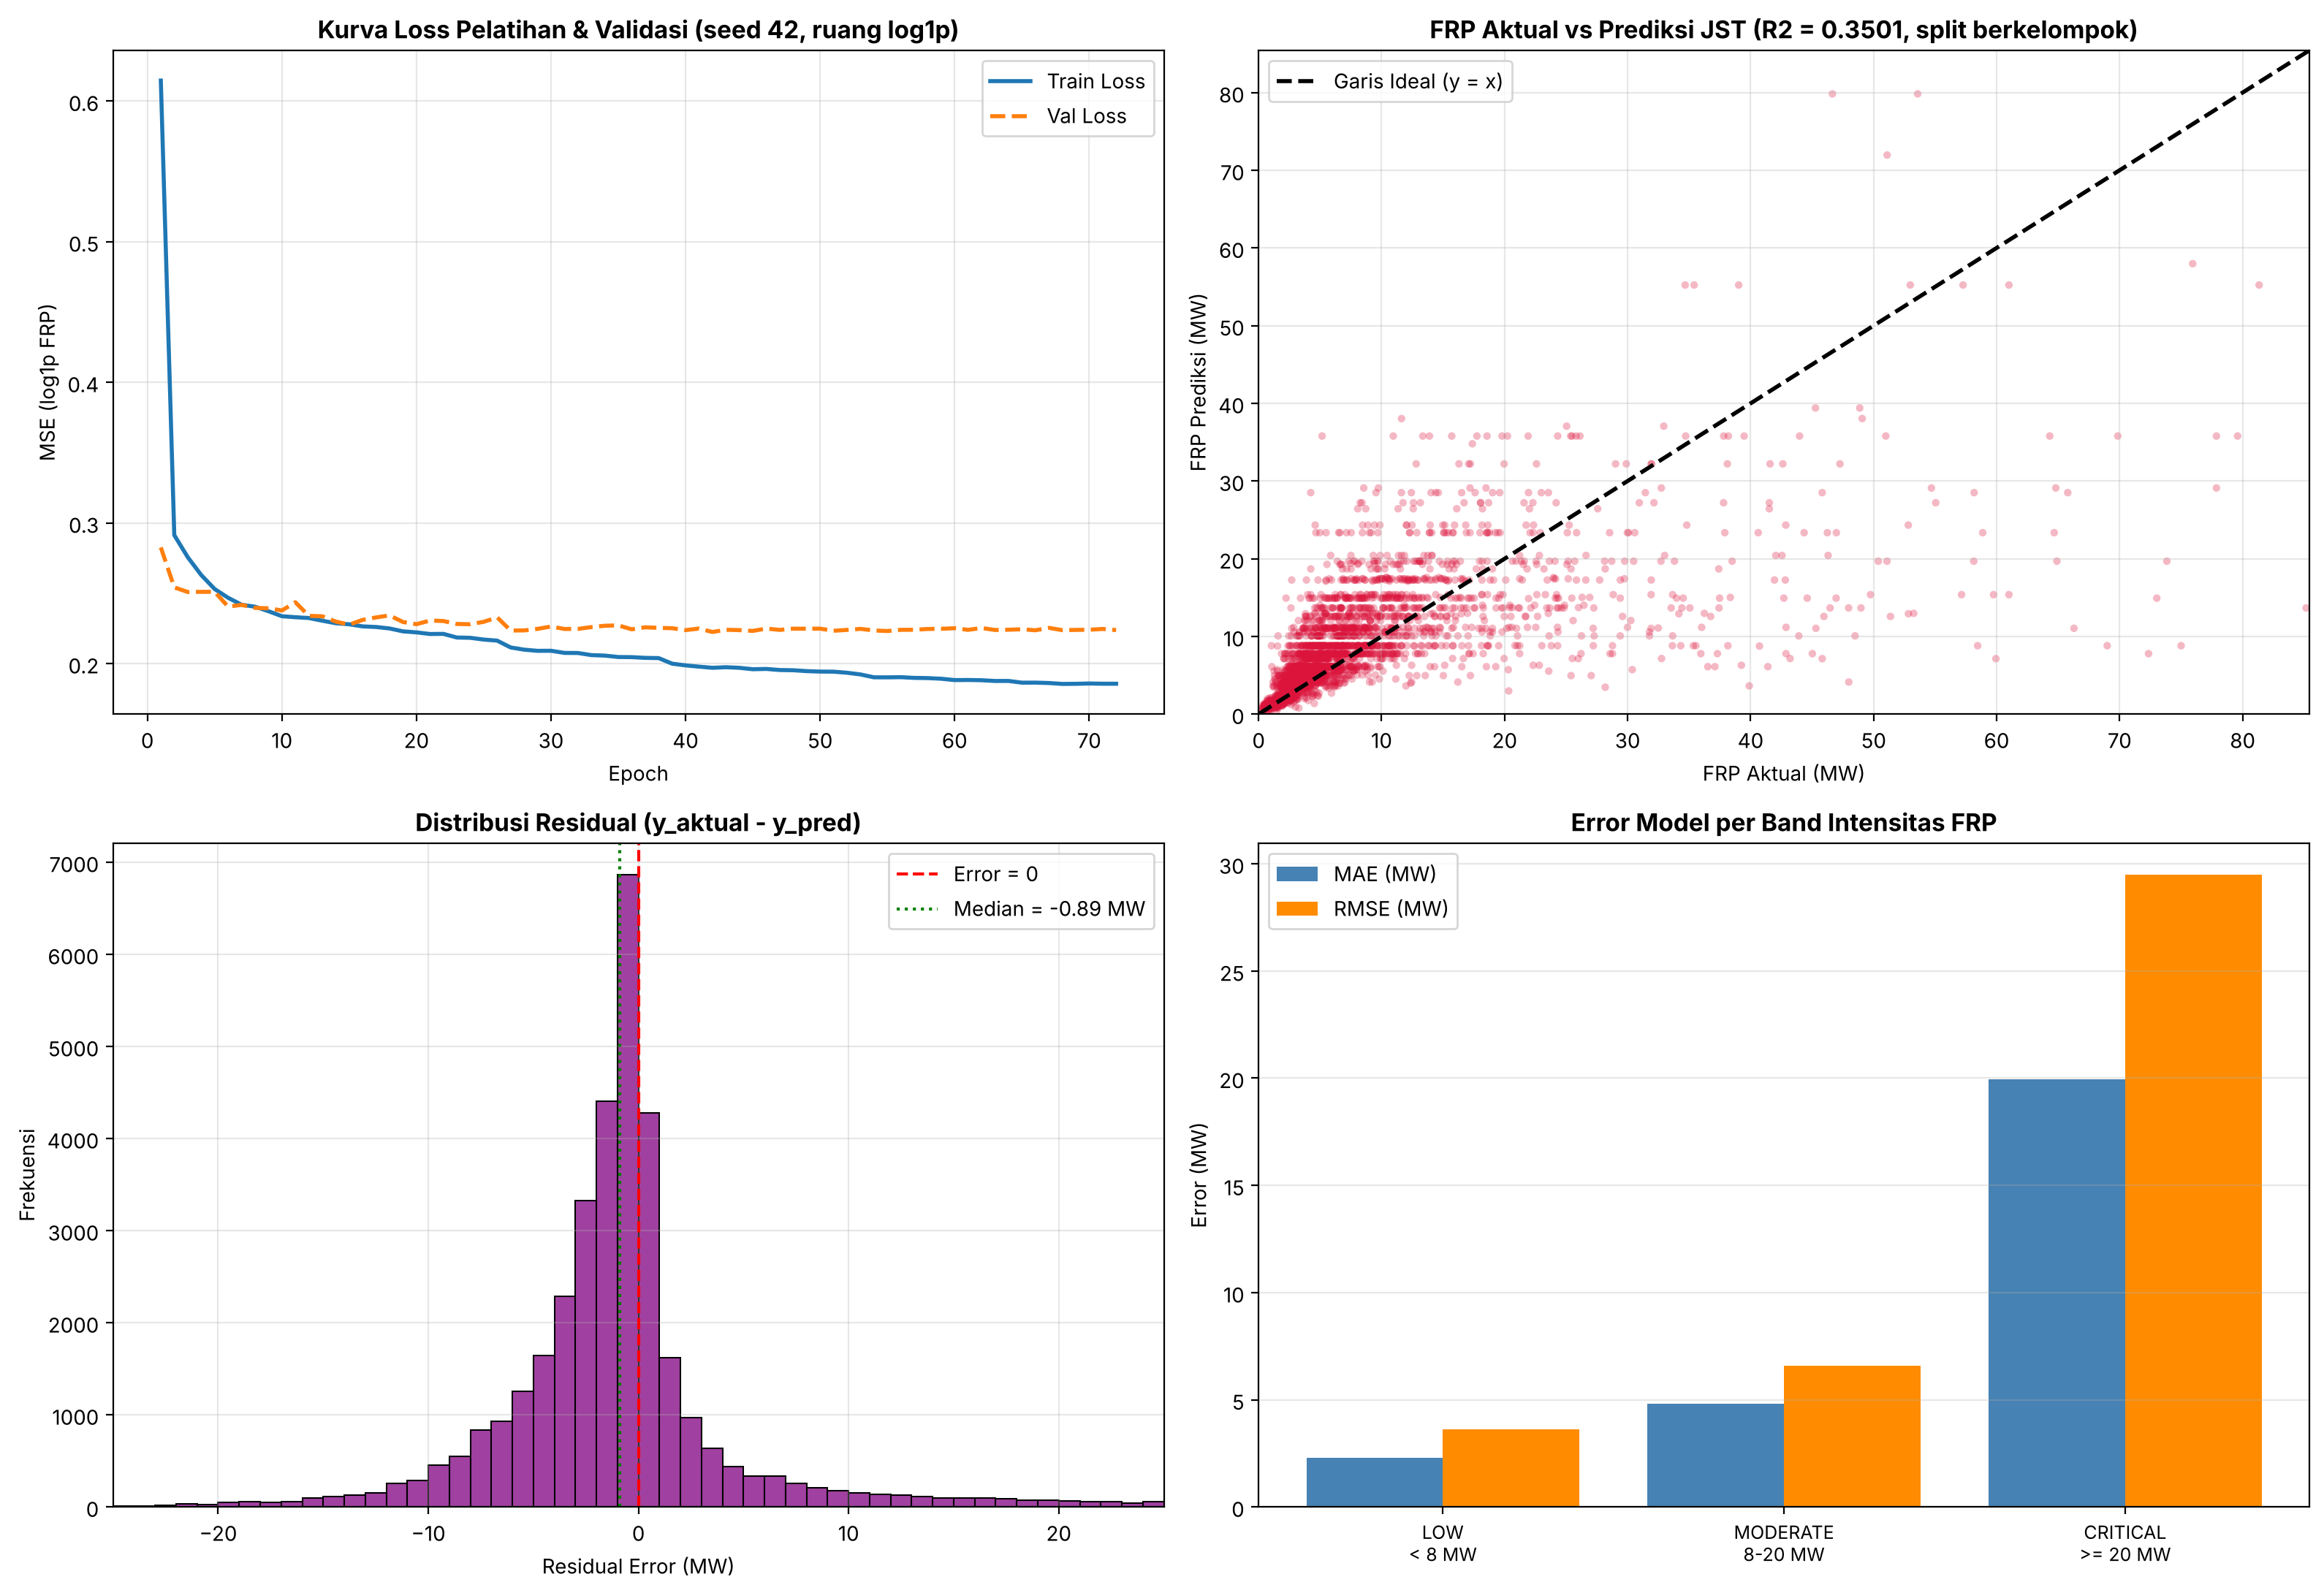

Grafik evaluasi disimpan ke: hasil_evaluasi_jst.png


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

ax = axes[0, 0]
ax.plot(range(1, epochs_run + 1), history['train_loss'], label='Train Loss', color='tab:blue', lw=2)
ax.plot(range(1, epochs_run + 1), history['val_loss'], label='Val Loss', color='tab:orange', lw=2, linestyle='--')
ax.set_title(f'Kurva Loss Pelatihan & Validasi (seed {SEED}, ruang log1p)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE (log1p FRP)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[0, 1]
subset = np.random.RandomState(SEED).choice(len(y_test), size=min(3000, len(y_test)), replace=False)
ax.scatter(y_test[subset], y_pred_cal[subset], alpha=0.3, color='crimson', edgecolors='none', s=14)
lim = max(np.percentile(y_test[subset], 99.5), np.percentile(y_pred_cal[subset], 99.5)) * 1.05
ax.plot([0, lim], [0, lim], '--k', lw=2, label='Garis Ideal (y = x)')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title(f'FRP Aktual vs Prediksi JST (R2 = {r2:.4f}, split berkelompok)', fontweight='bold')
ax.set_xlabel('FRP Aktual (MW)'); ax.set_ylabel('FRP Prediksi (MW)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1, 0]
residuals = y_test - y_pred_cal
sns.histplot(residuals, bins=np.arange(-25, 25.5, 1), color='purple', ax=ax)
ax.axvline(0, color='red', linestyle='--', label='Error = 0')
ax.axvline(np.median(residuals), color='green', linestyle=':',
           label=f'Median = {np.median(residuals):.2f} MW')
ax.set_xlim(-25, 25)
ax.set_title('Distribusi Residual (y_aktual - y_pred)', fontweight='bold')
ax.set_xlabel('Residual Error (MW)'); ax.set_ylabel('Frekuensi')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1, 1]
bands = [('LOW\n< 8 MW', y_test < 8),
         ('MODERATE\n8-20 MW', (y_test >= 8) & (y_test < 20)),
         ('CRITICAL\n>= 20 MW', y_test >= 20)]
x_pos = np.arange(len(bands))
maes = [mean_absolute_error(y_test[m], y_pred_cal[m]) for _, m in bands]
rmses = [np.sqrt(mean_squared_error(y_test[m], y_pred_cal[m])) for _, m in bands]
ax.bar(x_pos - 0.2, maes, 0.4, label='MAE (MW)', color='steelblue')
ax.bar(x_pos + 0.2, rmses, 0.4, label='RMSE (MW)', color='darkorange')
ax.set_xticks(x_pos); ax.set_xticklabels([b for b, _ in bands], fontsize=9)
ax.set_title('Error Model per Band Intensitas FRP', fontweight='bold')
ax.set_ylabel('Error (MW)'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('hasil_evaluasi_jst.png', dpi=300, bbox_inches='tight')
plt.show()
print('Grafik evaluasi disimpan ke: hasil_evaluasi_jst.png')

### 8b. Pembanding: Baseline, XGBoost & Ensemble

Pembanding dengan fitur dan split berkelompok yang sama:

- **Baseline konstan**: selalu memprediksi rata-rata FRP data latih (R² ≈ 0).
- **Regresi linear** pada `log1p(FRP)` + kalibrasi isotonic.
- **XGBoost `reg:tweedie`** (varians 1,5) — *gradient boosting* yang kuat untuk data tabular dan target non-negatif yang menceng.
- **Ensemble JST + XGBoost**, bobot dipilih pada data validasi.

Model final dipilih **pada data validasi** (bukan test), sehingga angka uji tetap jujur.

In [15]:
def add_row(rows, name, p):
    rows.append({'Model': name, **regression_metrics(y_test, p)})

final_rows = []
add_row(final_rows, 'Baseline: rata-rata data latih', np.full(len(y_test), y_train.mean()))

lin = LinearRegression().fit(X_train_scaled, np.log1p(y_train))
lin_val = np.expm1(np.clip(lin.predict(X_val_scaled), 0, LOG_CAP))
lin_test = np.expm1(np.clip(lin.predict(X_test_scaled), 0, LOG_CAP))
iso_lin = IsotonicRegression(out_of_bounds='clip').fit(lin_val, y_val)
add_row(final_rows, 'Baseline: regresi linear (log1p) + isotonic', iso_lin.predict(lin_test))
add_row(final_rows, f'JST ensemble {N_SEEDS} seed + isotonic', y_pred_cal)

# Kandidat model final dinilai pada VALIDASI, bukan test: (MSE val, fungsi prediksi, prediksi test, prediksi val)
candidates = {
    f'JST ensemble {N_SEEDS} seed + isotonic': (
        mse_of(y_val, y_pred_val_cal),
        lambda Z: np.clip(iso.predict(predict_jst(Z)), 0, None),
        y_pred_cal, y_pred_val_cal,
    )
}

try:
    import xgboost as xgb

    XGB_PARAMS = dict(objective='reg:tweedie', tweedie_variance_power=1.5,
                      n_estimators=4000, learning_rate=0.05, max_depth=6,
                      subsample=0.8, colsample_bytree=0.8, min_child_weight=2, reg_lambda=1.0,
                      early_stopping_rounds=100, random_state=SEED, tree_method='hist',
                      device='cuda' if torch.cuda.is_available() else 'cpu')
    xgb_model = xgb.XGBRegressor(**XGB_PARAMS)
    xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

    y_pred_xgb = np.clip(xgb_model.predict(X_test), 0, None)
    y_pred_xgb_val = np.clip(xgb_model.predict(X_val), 0, None)
    add_row(final_rows, 'XGBoost (tweedie)', y_pred_xgb)

    # Ensemble: bobot dipilih pada validasi
    best_w, best_ens_val = 0.5, float('inf')
    for w in np.arange(0, 1.001, 0.05):
        v = mse_of(y_val, np.clip(w * y_pred_val_cal + (1 - w) * y_pred_xgb_val, 0, None))
        if v < best_ens_val:
            best_ens_val, best_w = v, w

    ens_name = f'Ensemble JST {best_w:.2f} + XGB {1 - best_w:.2f}'
    y_pred_ens = np.clip(best_w * y_pred_cal + (1 - best_w) * y_pred_xgb, 0, None)
    y_pred_ens_val = np.clip(best_w * y_pred_val_cal + (1 - best_w) * y_pred_xgb_val, 0, None)
    add_row(final_rows, ens_name, y_pred_ens)

    def _ens_predict(Z):
        jst_part = np.clip(iso.predict(predict_jst(Z)), 0, None)
        return np.clip(best_w * jst_part + (1 - best_w) * np.clip(xgb_model.predict(Z), 0, None), 0, None)

    candidates[ens_name] = (best_ens_val, _ens_predict, y_pred_ens, y_pred_ens_val)
except ImportError:
    xgb = None
    print('xgboost tidak terpasang, benchmark dilewati.')

best_name = min(candidates, key=lambda k: candidates[k][0])
best_val_mse, predict_final, y_pred_final, y_pred_final_val = candidates[best_name]

bench_df = pd.DataFrame(final_rows).sort_values('MSE')
print(f'Model final terpilih (MSE validasi terkecil = {best_val_mse:.4f}): {best_name}')
print('PERBANDINGAN MODEL (data uji berkelompok):')
display(bench_df.round(4))

Model final terpilih (MSE validasi terkecil = 145.9785): Ensemble JST 0.60 + XGB 0.40
PERBANDINGAN MODEL (data uji berkelompok):


,Model,MSE,RMSE,MAE,R2,R2 (log)
4,Ensemble JST 0.60 + XGB 0.40,99.1371,9.9568,4.4980,0.3810,0.6415
3,XGBoost (tweedie),100.2567,10.0128,4.4742,0.3740,0.6376
2,JST ensemble 5 seed + isotonic,104.0917,10.2025,4.6380,0.3501,0.6298
1,Baseline: regresi linear (log1p) + isotonic,126.5971,11.2515,5.2372,0.2096,0.5332
0,Baseline: rata-rata data latih,160.2255,12.6580,7.1574,-0.0004,-0.2413


In [16]:
# Evaluasi per-band untuk MODEL FINAL terpilih
bands = [('LOW (< 8 MW)', y_test < 8),
         ('MODERATE (8-20 MW)', (y_test >= 8) & (y_test < 20)),
         ('CRITICAL (>= 20 MW)', y_test >= 20)]

rows = []
for label, mask in bands:
    rows.append({'Band FRP': label, 'n Sampel': int(mask.sum()),
                 'Proporsi': f'{mask.mean() * 100:.1f}%',
                 'MAE (MW)': round(mean_absolute_error(y_test[mask], y_pred_final[mask]), 3),
                 'RMSE (MW)': round(np.sqrt(mean_squared_error(y_test[mask], y_pred_final[mask])), 3),
                 'Bias (MW)': round(np.mean(y_pred_final[mask] - y_test[mask]), 3)})
rows.append({'Band FRP': 'SELURUH TEST', 'n Sampel': len(y_test), 'Proporsi': '100.0%',
             'MAE (MW)': round(mean_absolute_error(y_test, y_pred_final), 3),
             'RMSE (MW)': round(np.sqrt(mean_squared_error(y_test, y_pred_final)), 3),
             'Bias (MW)': round(np.mean(y_pred_final - y_test), 3)})
band_df = pd.DataFrame(rows)
print(f'PERFORMA MODEL FINAL ({best_name}) PER-BAND:')
display(band_df)

PERFORMA MODEL FINAL (Ensemble JST 0.60 + XGB 0.40) PER-BAND:


,Band FRP,n Sampel,Proporsi,MAE (MW),RMSE (MW),Bias (MW)
0,LOW (< 8 MW),23191,65.5%,2.260,3.495,1.939
1,MODERATE (8-20 MW),8758,24.7%,4.412,5.940,1.447
2,CRITICAL (>= 20 MW),3454,9.8%,19.742,29.063,-17.465
3,SELURUH TEST,35403,100.0%,4.498,9.957,-0.076


#### Ambang alarm CRITICAL dituning di data validasi

Prediksi regresi cenderung tertarik ke tengah, sehingga ambang 20 MW jarang terlewati dan banyak titik api CRITICAL lolos. Untuk keputusan mitigasi, yang penting adalah **recall CRITICAL** (titik api berbahaya tidak terlewat). Ambang alarm dipilih pada **data validasi** sebagai ambang terbesar yang masih memberi recall ≥ 70%, lalu diuji jujur pada data uji. Definisi kelas aktual tetap: CRITICAL = FRP ≥ 20 MW.

In [17]:
MODERATE_MW, CRITICAL_MW, TARGET_RECALL = 8.0, 20.0, 0.70

def crit_stats(y_true, p, thr):
    true_c, pred_c = y_true >= CRITICAL_MW, p >= thr
    tp = (true_c & pred_c).sum()
    return {'Recall CRITICAL': tp / max(true_c.sum(), 1),
            'Presisi CRITICAL': tp / max(pred_c.sum(), 1),
            'Porsi titik ditandai CRITICAL': pred_c.mean()}

def status(v, crit_thr=CRITICAL_MW):
    return np.where(v >= crit_thr, 2, np.where(v >= MODERATE_MW, 1, 0))

# ambang terbesar yang masih memberi recall >= TARGET_RECALL di VALIDASI
p_crit_val = np.sort(y_pred_final_val[y_val >= CRITICAL_MW])[::-1]
k = int(np.ceil(TARGET_RECALL * len(p_crit_val)))
CRITICAL_ALERT_MW = float(max(p_crit_val[k - 1], MODERATE_MW))

rows = []
for rule, thr in [('Ambang tetap 20 MW', CRITICAL_MW),
                  (f'Ambang alarm dituning di validasi ({CRITICAL_ALERT_MW:.2f} MW)', CRITICAL_ALERT_MW)]:
    acc = (status(y_test) == status(y_pred_final, thr)).mean()
    rows.append({'Aturan': rule, **crit_stats(y_test, y_pred_final, thr), 'Akurasi 3 kelas': acc})
print(f'Model final: {best_name}')
display(pd.DataFrame(rows).round(4))

labels = ['LOW', 'MODERATE', 'CRITICAL']
cm = confusion_matrix(status(y_test), status(y_pred_final, CRITICAL_ALERT_MW), labels=[0, 1, 2])
print(f'Confusion matrix data uji (ambang alarm {CRITICAL_ALERT_MW:.2f} MW):')
display(pd.DataFrame(cm, index=[f'Aktual {l}' for l in labels], columns=[f'Prediksi {l}' for l in labels]))

Model final: Ensemble JST 0.60 + XGB 0.40


,Aturan,Recall CRITICAL,Presisi CRITICAL,Porsi titik ditandai CRITICAL,Akurasi 3 kelas
0,Ambang tetap 20 MW,0.3848,0.5143,0.0730,0.7053
1,Ambang alarm dituning di validasi (13.76 MW),0.6789,0.3373,0.1964,0.6638


Confusion matrix data uji (ambang alarm 13.76 MW):


,Prediksi LOW,Prediksi MODERATE,Prediksi CRITICAL
Aktual LOW,17368,4816,1007
Aktual MODERATE,1371,3786,3601
Aktual CRITICAL,249,860,2345


### 8c. Uji Ketahanan: Kebocoran Split & Generalisasi ke Tahun Baru

1. **Bukti kebocoran**: persentase titik uji yang tetangga terdekatnya di data latih (overpass yang sama) memiliki FRP **identik**, untuk split acak vs split berkelompok.
2. **Validasi silang XGBoost** (cepat) dengan tiga skema: KFold acak (bocor), GroupKFold per overpass × sel, dan *forward-chaining* per tahun (latih tahun-tahun sebelumnya, uji tahun berikutnya; 2022–2025).
3. **Uji tahun baru untuk JST & XGBoost**: latih 2021–2023, validasi 2024, uji 2025.

In [18]:
overpass_arr = df_fe['overpass'].values
coords_rad = np.radians(df_fe[['latitude', 'longitude']].values)

def by_overpass(idx):
    return {k: v.values for k, v in pd.Series(idx).groupby(overpass_arr[idx])}

def share_identical_neighbour(idx_tr, idx_te):
    tr_by, hits = by_overpass(idx_tr), []
    for ov, te in by_overpass(idx_te).items():
        tr = tr_by.get(ov)
        if tr is None:
            hits.append(np.zeros(len(te), dtype=bool))
            continue
        _, j = BallTree(coords_rad[tr], metric='haversine').query(coords_rad[te], k=1)
        hits.append(y[tr][j[:, 0]] == y[te])
    return np.concatenate(hits).mean()

idx_rand_tr, idx_rand_te = train_test_split(idx_all, test_size=0.2, random_state=SEED)
print(f'Titik uji dengan tetangga latih ber-FRP identik | split acak      : '
      f'{share_identical_neighbour(idx_rand_tr, idx_rand_te) * 100:.1f}%')
print(f'Titik uji dengan tetangga latih ber-FRP identik | split berkelompok: '
      f'{share_identical_neighbour(idx_train_full, idx_test) * 100:.1f}%')

Titik uji dengan tetangga latih ber-FRP identik | split acak      : 16.6%


Titik uji dengan tetangga latih ber-FRP identik | split berkelompok: 0.4%


In [19]:
year_arr = df_fe['year'].values

def robust_row(name, y_true, p):
    return {'Skema evaluasi': name, **regression_metrics(y_true, p),
            'Recall CRITICAL (20 MW)': crit_stats(y_true, p, CRITICAL_MW)['Recall CRITICAL']}

if xgb is not None:
    def fit_xgb_idx(tr, va):
        m = xgb.XGBRegressor(**XGB_PARAMS)
        m.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], verbose=False)
        return m

    robust_rows = []
    oof = np.zeros(len(y))
    for tr, te in KFold(n_splits=5, shuffle=True, random_state=SEED).split(X):
        tr2, va = train_test_split(tr, test_size=0.2, random_state=SEED)
        oof[te] = np.clip(fit_xgb_idx(tr2, va).predict(X[te]), 0, None)
    robust_rows.append(robust_row('KFold acak 5-fold (bocor)', y, oof))

    oof = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=5).split(X, y, groups):
        tr2, va = grouped_split(tr, test_size=0.2)
        oof[te] = np.clip(fit_xgb_idx(tr2, va).predict(X[te]), 0, None)
    robust_rows.append(robust_row('GroupKFold 5-fold (overpass x sel 0,5°)', y, oof))

    y_fc, p_fc = [], []
    for yr in sorted(np.unique(year_arr))[1:]:
        tr_all, te = np.where(year_arr < yr)[0], np.where(year_arr == yr)[0]
        tr2, va = grouped_split(tr_all, test_size=0.2)
        y_fc.append(y[te])
        p_fc.append(np.clip(fit_xgb_idx(tr2, va).predict(X[te]), 0, None))
    robust_rows.append(robust_row('Forward-chaining per tahun (uji 2022–2025)',
                                  np.concatenate(y_fc), np.concatenate(p_fc)))
    print('VALIDASI SILANG XGBOOST — skor gabungan out-of-fold:')
    display(pd.DataFrame(robust_rows).round(4))

VALIDASI SILANG XGBOOST — skor gabungan out-of-fold:


,Skema evaluasi,MSE,RMSE,MAE,R2,R2 (log),Recall CRITICAL (20 MW)
0,KFold acak 5-fold (bocor),113.5318,10.6551,4.2789,0.4134,0.6773,0.3926
1,"GroupKFold 5-fold (overpass x sel 0,5°)",122.1191,11.0507,4.6568,0.3691,0.6286,0.3403
2,Forward-chaining per tahun (uji 2022–2025),149.5048,12.2272,5.6368,0.2427,0.5090,0.3970


In [20]:
# Uji tahun baru: latih 2021-2023, validasi 2024, uji 2025
t_tr = np.where(year_arr <= 2023)[0]
t_va = np.where(year_arr == 2024)[0]
t_te = np.where(year_arr == 2025)[0]

scaler_t = StandardScaler().fit(X[t_tr])
net_t, _ = train_jst(scaler_t.transform(X[t_tr]), y[t_tr], scaler_t.transform(X[t_va]), y[t_va],
                     verbose=False, **BEST_CFG)
cap_t = np.log1p(y[t_tr].max())
p_va_t = jst_predict(net_t, scaler_t.transform(X[t_va]), cap_t)
p_te_t = jst_predict(net_t, scaler_t.transform(X[t_te]), cap_t)
iso_t = IsotonicRegression(out_of_bounds='clip').fit(p_va_t, y[t_va])

temporal_rows = [robust_row('JST + isotonic (latih 2021–2023, uji 2025)', y[t_te],
                            np.clip(iso_t.predict(p_te_t), 0, None))]
if xgb is not None:
    temporal_rows.append(robust_row('XGBoost (latih 2021–2023, uji 2025)', y[t_te],
                                    np.clip(fit_xgb_idx(t_tr, t_va).predict(X[t_te]), 0, None)))
print(f'UJI TAHUN BARU: latih {len(t_tr):,} | validasi {len(t_va):,} | uji {len(t_te):,} sampel')
display(pd.DataFrame(temporal_rows).round(4))

UJI TAHUN BARU: latih 120,271 | validasi 31,514 | uji 32,670 sampel


,Skema evaluasi,MSE,RMSE,MAE,R2,R2 (log),Recall CRITICAL (20 MW)
0,"JST + isotonic (latih 2021–2023, uji 2025)",164.2275,12.8151,6.9567,0.2023,0.3827,0.5040
1,"XGBoost (latih 2021–2023, uji 2025)",162.3469,12.7415,6.5839,0.2115,0.4227,0.4539


### 8d. Studi Ablasi: Dari Desain Tahap 1 ke Model Final

Setiap langkah menambahkan satu perubahan terhadap rancangan awal di dokumen Tahap 1, dilatih dan diuji pada split berkelompok yang sama, sehingga kontribusi tiap perubahan terlihat. Desain Tahap 1: 8 fitur, MLP 128-64-32 ReLU (dropout 0,2/0,1), Adam lr 0,001, batch 64, 30 epoch, loss MSE pada FRP mentah. Hasil disimpan ke `hasil_ablasi_jst.csv`; set `RUN_ABLATION = False` untuk memakai hasil tersimpan.

1. Desain Tahap 1 (8 fitur, ReLU, MSE FRP mentah, 30 epoch) selesai


2. + target log1p, LR scheduler & early stopping selesai
3. + kalibrasi isotonic selesai


4. + 18 fitur turunan (flag I4, termal, waktu, kerapatan) & arsitektur hasil tuning selesai


5. + 11 fitur klaster api selesai
6. + 30 fitur cuaca lag (67 fitur, 1 seed) selesai
7. + ensemble 5 seed (JST final) selesai


,Langkah,MSE,RMSE,MAE,R2,R2 (log)
0,"1. Desain Tahap 1 (8 fitur, ReLU, MSE FRP ment...",107.6065,10.3734,4.8237,0.3282,0.5535
1,"2. + target log1p, LR scheduler & early stopping",113.2277,10.6409,4.5077,0.2931,0.5934
2,3. + kalibrasi isotonic,110.3094,10.5028,5.0669,0.3113,0.5415
3,"4. + 18 fitur turunan (flag I4, termal, waktu,...",110.7454,10.5236,5.0483,0.3086,0.5484
4,5. + 11 fitur klaster api,106.5522,10.3224,4.7334,0.3347,0.6157
5,"6. + 30 fitur cuaca lag (67 fitur, 1 seed)",104.3264,10.2140,4.6615,0.3486,0.6243
6,7. + ensemble 5 seed (JST final),104.0917,10.2025,4.6380,0.3501,0.6298


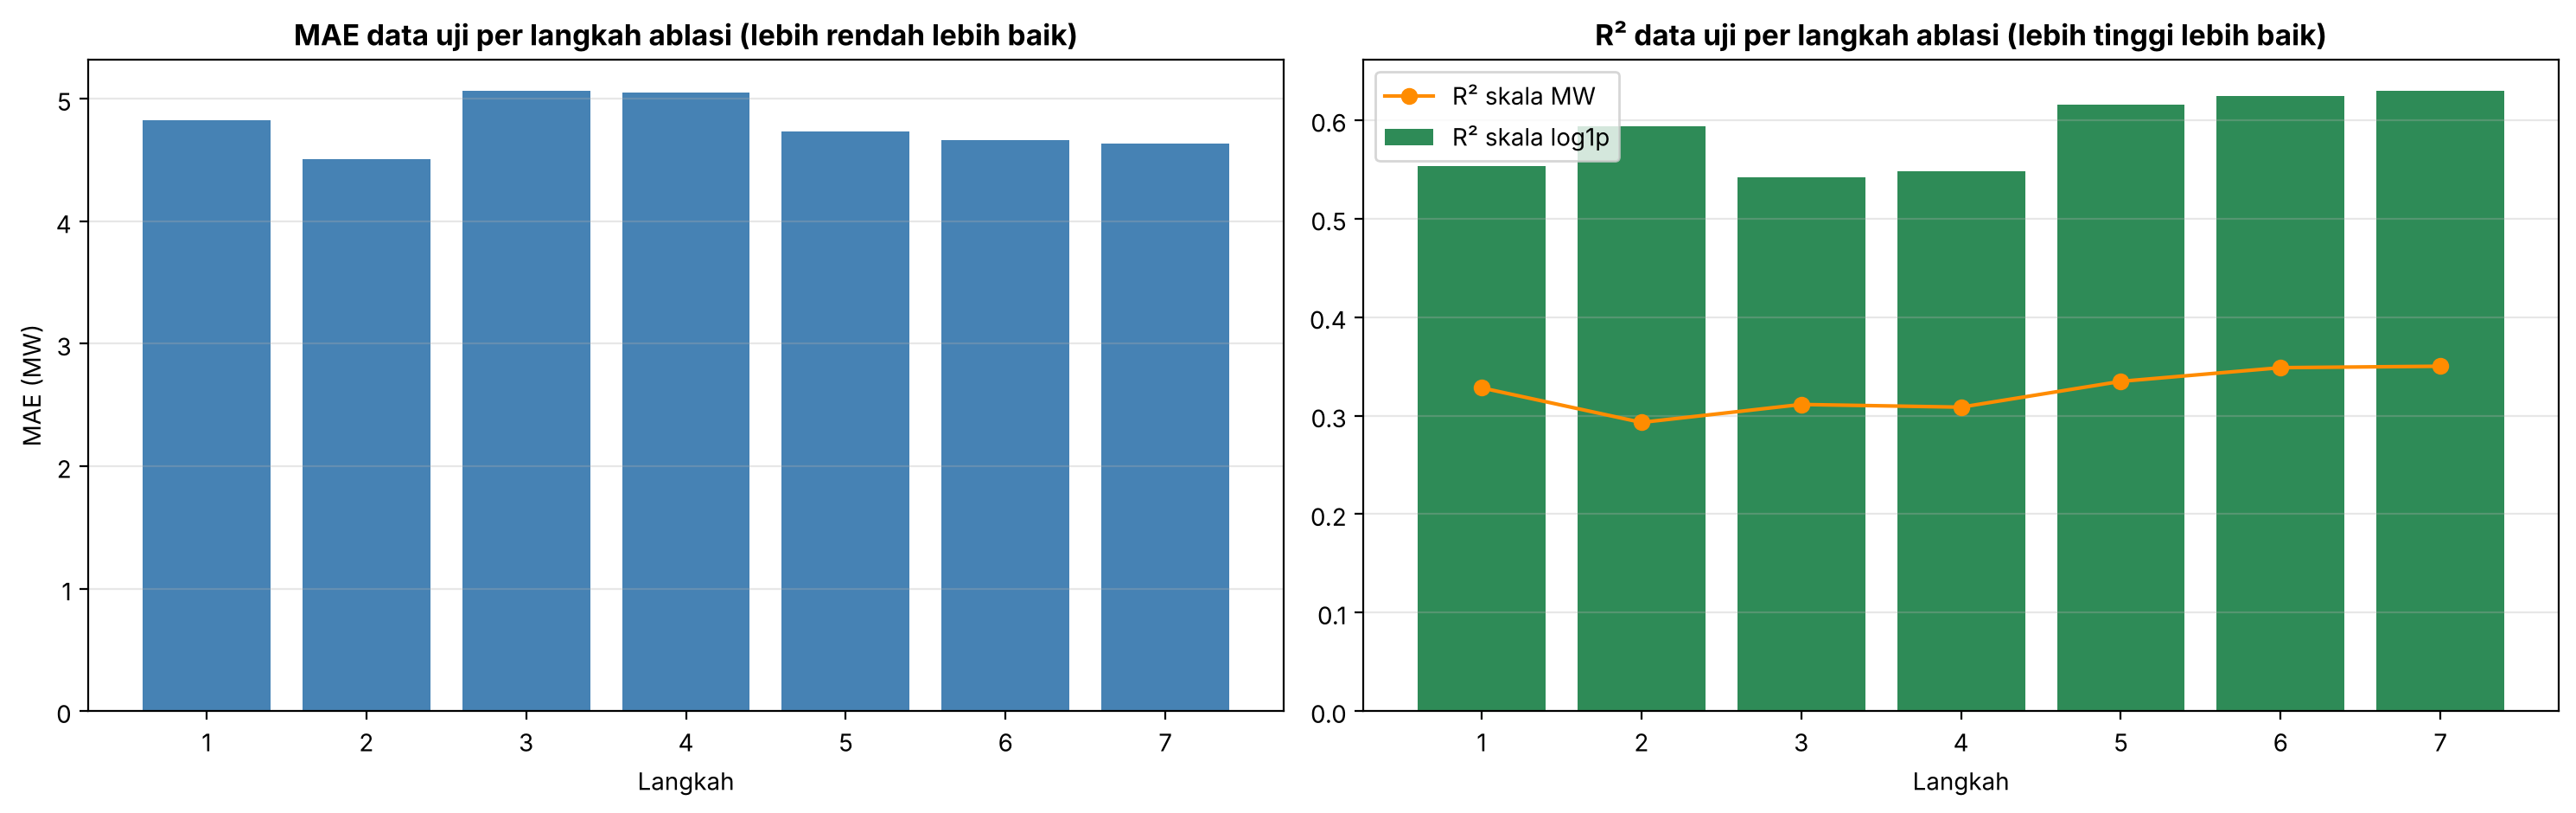

In [21]:
if RUN_ABLATION:
    def cols_of(names):
        return [FEATURES.index(c) for c in names]

    STAGE1 = dict(hidden=(128, 64, 32), drop=(0.2, 0.1, 0.0), act='relu', batchnorm=False,
                  lr=1e-3, batch_size=64, optimizer_name='adam')
    SET8 = cols_of(BASE_FEATURES)
    SET_DERIVED = cols_of(BASE_FEATURES + I4_FLAGS + THERMAL + TEMPORAL + DENSITY)
    SET_CLUSTER = cols_of(BASE_FEATURES + I4_FLAGS + THERMAL + TEMPORAL + DENSITY + CLUSTER)

    def ablation_preds(cols, **c):
        sc = StandardScaler().fit(X_train[:, cols])
        net, _ = train_jst(sc.transform(X_train[:, cols]), y_train, sc.transform(X_val[:, cols]), y_val,
                           verbose=False, **c)
        return jst_predict(net, sc.transform(X_val[:, cols]), LOG_CAP), jst_predict(net, sc.transform(X_test[:, cols]), LOG_CAP)

    def calibrated(pv, pt):
        return IsotonicRegression(out_of_bounds='clip').fit(pv, y_val).predict(pt)

    ablation_rows = []
    def add_step(name, p):
        ablation_rows.append({'Langkah': name, **regression_metrics(y_test, p)})
        print(f'{name} selesai')

    _, pt1 = ablation_preds(SET8, **STAGE1, log_target=False, use_scheduler=False, epochs_max=30, patience=0)
    add_step('1. Desain Tahap 1 (8 fitur, ReLU, MSE FRP mentah, 30 epoch)', pt1)
    pv2, pt2 = ablation_preds(SET8, **STAGE1)
    add_step('2. + target log1p, LR scheduler & early stopping', pt2)
    add_step('3. + kalibrasi isotonic', calibrated(pv2, pt2))
    add_step('4. + 18 fitur turunan (flag I4, termal, waktu, kerapatan) & arsitektur hasil tuning',
             calibrated(*ablation_preds(SET_DERIVED, **BEST_CFG)))
    add_step('5. + 11 fitur klaster api', calibrated(*ablation_preds(SET_CLUSTER, **BEST_CFG)))
    pv0, pt0 = jst_predict(models[0], X_val_scaled, LOG_CAP), jst_predict(models[0], X_test_scaled, LOG_CAP)
    add_step('6. + 30 fitur cuaca lag (67 fitur, 1 seed)', calibrated(pv0, pt0))
    add_step(f'7. + ensemble {N_SEEDS} seed (JST final)', y_pred_cal)

    ablation_df = pd.DataFrame(ablation_rows)
    ablation_df.to_csv('hasil_ablasi_jst.csv', index=False)
else:
    ablation_df = pd.read_csv('hasil_ablasi_jst.csv')
display(ablation_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
short = [str(s).split(' ')[0].rstrip('.') for s in ablation_df['Langkah']]
axes[0].bar(short, ablation_df['MAE'], color='steelblue')
axes[0].set_title('MAE data uji per langkah ablasi (lebih rendah lebih baik)', fontweight='bold')
axes[0].set_xlabel('Langkah'); axes[0].set_ylabel('MAE (MW)')
axes[1].bar(short, ablation_df['R2 (log)'], color='seagreen', label='R² skala log1p')
axes[1].plot(short, ablation_df['R2'], 'o-', color='darkorange', label='R² skala MW')
axes[1].set_title('R² data uji per langkah ablasi (lebih tinggi lebih baik)', fontweight='bold')
axes[1].set_xlabel('Langkah'); axes[1].legend()
for ax in axes:
    ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('hasil_ablasi_jst.png', dpi=300, bbox_inches='tight')
plt.show()

### 9. Simulasi Inferensi: Estimasi Keganasan Titik Api Baru untuk Mitigasi Lapangan

Simulasi memakai **hari dengan titik api terbanyak pada tahun terakhir data**. Titik api contoh diperlakukan sebagai deteksi pada overpass hari itu (siang atau malam sesuai `is_day`): fitur kerapatan dan klaster api dihitung ulang bersama seluruh deteksi overpass tersebut, dan fitur cuaca lag diambil dari deteksi terdekat pada tanggal yang sama (cuaca berada pada sel 0,5°). `acq_time` dalam **UTC**; S-NPP melintasi Kalimantan sekitar 04–07 UTC (siang) dan 16–19 UTC (malam).

Kategori memakai **ambang alarm CRITICAL hasil tuning** pada data validasi.

In [22]:
last_year = df_fe['year'].max()
SIM_DATE = df_fe.loc[df_fe['year'] == last_year, 'acq_date'].value_counts().idxmax()
sample_hotspots = pd.DataFrame([
    {'lokasi': 'Katingan (Hutan Gambut Pekat)', 'latitude': -2.05, 'longitude': 113.35, 'bright_ti4': 365.2, 'scan': 0.40, 'track': 0.38, 'bright_ti5': 304.5, 'is_day': 1, 'confidence_score': 3, 'acq_time': 605},
    {'lokasi': 'Seruyan (Dekat Pemukiman)', 'latitude': -2.52, 'longitude': 112.21, 'bright_ti4': 342.1, 'scan': 0.48, 'track': 0.42, 'bright_ti5': 298.0, 'is_day': 1, 'confidence_score': 2, 'acq_time': 625},
    {'lokasi': 'Ketapang (Titik Api Malam Hari)', 'latitude': -1.82, 'longitude': 110.15, 'bright_ti4': 324.6, 'scan': 0.55, 'track': 0.45, 'bright_ti5': 291.3, 'is_day': 0, 'confidence_score': 1, 'acq_time': 1750}
])
sample_hotspots['acq_date'] = SIM_DATE
sample_hotspots['overpass'] = SIM_DATE.strftime('%Y-%m-%d') + '_' + np.where(sample_hotspots['is_day'] == 1, 'D', 'N')

# Cuaca lag: dari deteksi terdekat pada tanggal yang sama
same_day = df_fe[df_fe['acq_date'] == SIM_DATE].reset_index(drop=True)
_, nearest = BallTree(np.radians(same_day[['latitude', 'longitude']].values), metric='haversine').query(
    np.radians(sample_hotspots[['latitude', 'longitude']].values), k=1)
sample_hotspots[WEATHER_LAG] = same_day.loc[nearest[:, 0], WEATHER_LAG].values

sim = add_temporal_features(add_thermal_features(fix_i4(sample_hotspots))).reset_index(drop=True)
pool_cols = ['overpass', 'latitude', 'longitude', 'bright_ti4', 'bright_ti5', 'pixel_area', 'ti4_saturated']
pool = pd.concat([df_fe.loc[df_fe['overpass'].isin(sim['overpass']), pool_cols], sim[pool_cols]], ignore_index=True)
sim = pd.concat([sim,
                 add_density_features(sim, build_density_tables(pool)),
                 add_cluster_features(pool).iloc[-len(sim):].reset_index(drop=True)], axis=1)

X_sim = sim[FEATURES].values.astype(np.float32)
pred_frp = predict_final(X_sim)
sample_hotspots['Prediksi FRP (MW)'] = np.round(pred_frp, 2)

def kategori_bahaya(frp_val):
    if frp_val >= CRITICAL_ALERT_MW:
        return 'CRITICAL / TINGGI (Prioritaskan Water Bombing Helikopter)'
    elif frp_val >= MODERATE_MW:
        return 'MODERATE / SEDANG (Tim Manggala Agni Darat)'
    else:
        return 'LOW / RINGAN (Pemantauan Satelit Berkala)'

sample_hotspots['Status & Rekomendasi Mitigasi'] = sample_hotspots['Prediksi FRP (MW)'].apply(kategori_bahaya)
print(f'Tanggal simulasi: {SIM_DATE.date()} | Model: {best_name} | ambang alarm CRITICAL: {CRITICAL_ALERT_MW:.2f} MW')
display(sample_hotspots[['lokasi', 'latitude', 'longitude', 'bright_ti4', 'acq_time', 'overpass',
                         'Prediksi FRP (MW)', 'Status & Rekomendasi Mitigasi']])

Tanggal simulasi: 2025-09-24 | Model: Ensemble JST 0.60 + XGB 0.40 | ambang alarm CRITICAL: 13.76 MW


,lokasi,latitude,longitude,bright_ti4,acq_time,overpass,Prediksi FRP (MW),Status & Rekomendasi Mitigasi
0,Katingan (Hutan Gambut Pekat),-2.05,113.35,365.2,605,2025-09-24_D,31.80,CRITICAL / TINGGI (Prioritaskan Water Bombing ...
1,Seruyan (Dekat Pemukiman),-2.52,112.21,342.1,625,2025-09-24_D,13.04,MODERATE / SEDANG (Tim Manggala Agni Darat)
2,Ketapang (Titik Api Malam Hari),-1.82,110.15,324.6,1750,2025-09-24_N,5.67,LOW / RINGAN (Pemantauan Satelit Berkala)


### 10. Kesimpulan

1. **Model final** adalah ensemble **JST 0,60 + XGBoost 0,40** (bobot dipilih di data validasi): MSE 99,14; RMSE 9,96 MW; MAE 4,50 MW; R² 0,381; R² skala log 0,642 pada data uji berkelompok. JST memegang bobot terbesar.
2. **JST sendiri** (ensemble 5 MLP 67-512-256-128-1, Tanh, kalibrasi isotonic) mencapai R² 0,350 dan MAE 4,64 MW — jauh di atas regresi linear (R² 0,210) dan baseline konstan, sedikit di bawah XGBoost (R² 0,374) pada data tabular sebesar ini. Gabungan keduanya paling baik.
3. **Fitur klaster api** tetap perbaikan terbesar (studi ablasi langkah 4 → 5: R² 0,309 → 0,335; R² skala log 0,548 → 0,616; MAE 5,05 → 4,73 MW). **Fitur cuaca lag** menambah lagi (langkah 5 → 6: R² 0,335 → 0,349; MAE 4,73 → 4,66 MW). Ensemble 5 seed menambah sedikit (R² 0,349 → 0,350).
4. **Hyperparameter tuning** memilih Tanh, 512-256-128, lr 0,002, batch 512, tetapi selisih antar-konfigurasi kecil (MSE validasi log 0,2224–0,2272, ±2%). Informasi pada fitur lebih menentukan daripada arsitektur.
5. **Desain Tahap 1** (MSE pada FRP mentah) punya MSE cukup rendah (107,61) karena langsung mengoptimasi MSE, tetapi R² skala log-nya (0,554) jauh di bawah JST final (0,630). Kalibrasi isotonic menurunkan MSE tetapi menaikkan MAE (langkah 2 → 3: MAE 4,51 → 5,07 MW), karena prediksi digeser ke arah rata-rata.
6. **Untuk mitigasi**, ambang alarm 13,76 MW (dituning di validasi) menangkap 67,9% titik api CRITICAL (38,5% dengan ambang 20 MW), dengan presisi 33,7% dan 19,6% titik ditandai.
7. **Evaluasi jujur penting.** Split acak membocorkan piksel kembar (16,6% titik uji vs 0,4% pada split berkelompok). XGBoost mendapat R² 0,413 dengan split acak, 0,369 dengan GroupKFold, dan 0,243 dengan *forward-chaining* per tahun. Pada uji tahun baru (uji 2025), R² JST 0,202 dan XGBoost 0,212: memprediksi tahun yang belum pernah dilihat jauh lebih sulit, apalagi FRP 2025 lebih tinggi (median 6,40 MW dan 13,0% CRITICAL, dibanding 5,47–5,52 MW dan 8,3–8,8% pada 2021–2023).

**Batasan yang tersisa**:
- FRP produk 375 m dihitung dari kanal M13 (750 m) yang tidak ada di CSV FIRMS, dan 3,4% piksel I4 jenuh pada 367 K; kelas CRITICAL masih *underestimate* (bias −17,5 MW).
- Cuaca NASA POWER berresolusi kasar (sel 0,5°, harian), sehingga korelasinya dengan FRP per piksel lemah (|Spearman| ≤ 0,14).
- Distribusi FRP bergeser antar-tahun (2023 tahun El Niño dengan titik api terbanyak; 2024–2025 FRP lebih tinggi).

**Arah pengembangan**: tambahkan deteksi NOAA-20/NOAA-21, peta gambut dan tutupan lahan, riwayat FRP per lokasi, serta model spasial–temporal; evaluasi selalu dengan skema berkelompok atau per tahun.